# Phân tích dữ liệu thương hiệu Cocoon trên Hasaki và Shopee

**Dữ liệu (4 file Excel):** `products_hasaki`, `reviews_hasaki`, `cocoon_shopee_products`, `cocoon_shopee_reviews`.

| Phần | Bài toán kinh doanh | Kỹ thuật |
|---|---|---|
| A1 | Phát hiện sớm review tiêu cực (≤ 3★) trên Shopee | Logistic Regression, Decision Tree, Random Forest |
| A2 | Doanh thu 30 ngày của sản phẩm Hasaki phụ thuộc vào đâu | Linear Regression, Decision Tree, Random Forest |
| B1 | Sản phẩm nào đang "khỏe", sản phẩm nào đang "nguội" | Phân khúc RFM theo luật |
| B2 | Để dữ liệu tự chia nhóm sản phẩm | K-Means |
| B3 | Khách hay nhắc những khía cạnh nào cùng nhau | Apriori, FP-Growth |
| C | Khách đang nói về những chủ đề nào (mở rộng, ngoài môn học) | TF-IDF + NMF |

**Cách chạy:** menu *Runtime → Run all*, chọn đủ 4 file Excel khi được hỏi.

**Lưu ý về phần nhận xét:** các ô nhận xét kinh tế dùng số liệu của lần chạy với `RANDOM_STATE = 42` trên đúng 4 file này (scikit-learn 1.8, pandas 3.0). Nếu đổi dữ liệu, tham số hoặc phiên bản thư viện, các chỉ số có thể lệch nhẹ (nhất là Decision Tree ở phần A1); hãy đọc lại kết quả rồi chỉnh nhận xét cho khớp.

In [1]:
# ---- Thư viện ----
import re, time, warnings
from itertools import combinations
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import NMF, PCA
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_squared_error, precision_score, r2_score,
                             recall_score, roc_auc_score, silhouette_score)
from sklearn.model_selection import (KFold, ParameterGrid, RepeatedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# Luật kết hợp: Colab đã cài sẵn mlxtend. Nếu chạy trên máy cá nhân hãy chạy:  pip install mlxtend
from mlxtend.frequent_patterns import apriori, fpgrowth

warnings.filterwarnings("ignore")

# ---- Tham số có thể chỉnh ----
RANDOM_STATE = 42
NEG_STAR_MAX = 3            # review <= 3 sao = "Tiêu cực" (lớp cần dự báo)
THRESHOLD = 0.4             # ngưỡng xác suất để gắn cờ review cho CSKH (chọn ở phần A1)
RFM_WINDOW_DAYS = 365       # Frequency = số review trong N ngày gần nhất
K_CLUSTERS = None           # None = tự chọn k theo Silhouette trong khoảng 3-6
MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT = 0.03, 0.40, 1.0    # luật kết hợp
N_TOPICS = 8                # số chủ đề NMF

# ---- Thư mục kết quả, màu sắc, hàm hỗ trợ ----
FIG_DIR, TAB_DIR = Path("outputs/figures"), Path("outputs/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
CYCLE = [BLUE, ORANGE, AQUA, "#eda100", "#e87ba4", "#008300", "#6250d6", RED]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "axes.prop_cycle": plt.cycler(color=CYCLE),
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 100})


def finish(fig, name, title=None):
    # Lưu biểu đồ vào outputs/figures và hiển thị
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def save_table(df, name, index=False):
    # Lưu bảng kết quả ra outputs/tables (CSV, mở được bằng Excel)
    df.to_csv(TAB_DIR / f"{name}.csv", index=index, encoding="utf-8-sig")


def split_70_15_15(n, y=None):
    # Chia 70% Train / 15% Validation / 15% Test. Có y thì giữ nguyên tỉ lệ lớp (stratify).
    idx = np.arange(n)
    i_tr, i_tmp = train_test_split(idx, test_size=0.30, random_state=RANDOM_STATE, stratify=y)
    i_va, i_te = train_test_split(i_tmp, test_size=0.50, random_state=RANDOM_STATE,
                                  stratify=None if y is None else y[i_tmp])
    return i_tr, i_va, i_te


def chon_tham_so(Model, co_dinh, luoi, Xtr, ytr, Xva, yva, cham, cang_cao_cang_tot):
    # Thử mọi tổ hợp siêu tham số trong `luoi`: huấn luyện trên Train, chấm điểm trên Validation.
    best_s, best_p = None, {}
    for p in ParameterGrid(luoi):
        s = cham(yva, Model(**co_dinh, **p).fit(Xtr, ytr).predict(Xva))
        if best_s is None or (s > best_s if cang_cao_cang_tot else s < best_s):
            best_s, best_p = s, p
    return best_p

## 1. Đọc, làm sạch và chuẩn hóa dữ liệu

1. Đọc 4 file và **thống nhất tên cột** giữa hai sàn (ví dụ `Lượt bán (30 ngày)` → `Lượt bán`; `% Giảm giá` × 100 → `Giảm giá (%)`).
2. **Gộp review hai sàn** vào một bảng (cột `san`), đổi ngày về kiểu datetime, "Đã mua hàng" về 0/1.
3. **Làm sạch văn bản:** bỏ thẻ HTML, bỏ đường link, chữ thường, gộp khoảng trắng; loại review rỗng và review trùng.
4. Tạo đặc trưng đơn giản: độ dài (ký tự, số từ), số dấu `!`.
5. **Kiểm tra chất lượng:** số bản ghi, phân bố số sao, review không khớp mã sản phẩm.

In [3]:
# ---- Tìm và đọc 4 file Excel ----
# Colab: file tải lên nằm ở /content. Chạy trên máy cá nhân: đặt 4 file cùng thư mục với notebook.
DATA_DIR = Path("/content") if Path("/content").exists() else Path(".")

# Mỗi file được nhận ra bằng từ khóa trong tên (không phân biệt hoa/thường, bỏ qua "_" và " (1)")
FILES = {"ph": ("products", "hasaki"), "rh": ("reviews", "hasaki"),
         "sp": ("shopee", "products"), "sr": ("shopee", "reviews")}


def tim_file(*tu_khoa):
    ds = [p for p in DATA_DIR.glob("*.xlsx") if all(k in p.name.lower() for k in tu_khoa)]
    return max(ds, key=lambda p: p.stat().st_mtime) if ds else None


if any(tim_file(*k) is None for k in FILES.values()):
    try:
        from google.colab import files
        print("Hãy chọn đủ 4 file .xlsx: products và reviews của Hasaki, products và reviews của Shopee")
        files.upload()
    except ImportError:
        pass

paths = {k: tim_file(*v) for k, v in FILES.items()}
thieu = [k for k, p in paths.items() if p is None]
if thieu:
    raise FileNotFoundError(f"Còn thiếu file: {thieu}. Kiểm tra lại tên file và thư mục {DATA_DIR}")

ph = pd.read_excel(paths["ph"])                                  # sản phẩm Hasaki
rh = pd.read_excel(paths["rh"])                                  # review Hasaki
sp = pd.read_excel(paths["sp"], sheet_name="Products")           # sản phẩm Shopee
rs = pd.read_excel(paths["sr"])                                  # review Shopee
print("Đã đọc:", *[p.name for p in paths.values()], sep="\n  - ")

Đã đọc:
  - products_hasaki.xlsx
  - Reviews_hasaki.xlsx
  - cocoon_shopee_products_.xlsx
  - cocoon_shopee_reviews__.xlsx


In [4]:
# ---- Thống nhất tên cột và gộp sản phẩm hai sàn ----
ph = ph.rename(columns={"Lượt bán (30 ngày)": "Lượt bán", "Tổng lượt đánh giá tích lũy": "Tổng lượt đánh giá",
                        "% Chênh lệch giá": "Giảm giá (%)"})
sp["Giảm giá (%)"] = sp["% Giảm giá"] * 100
ph["Sàn"], sp["Sàn"] = "Hasaki", "Shopee"
products = pd.concat([ph, sp], ignore_index=True)

# ---- Gộp review hai sàn ----
COLS = {"Mã SP": "ma_sp", "Số sao (review)": "sao", "Nội dung review": "text",
        "Ngày review": "date", "Đã mua hàng": "verified"}


def lay_cot(df, san):
    return df.rename(columns=COLS)[list(COLS.values())].assign(san=san)


reviews = pd.concat([lay_cot(rh, "Hasaki"), lay_cot(rs, "Shopee")], ignore_index=True)
reviews["date"] = pd.to_datetime(reviews["date"], errors="coerce")
reviews["verified"] = (reviews["verified"].astype(str).str.strip() == "Có").astype(int)


def clean_text(s):
    s = str(s) if pd.notna(s) else ""
    s = re.sub(r"<[^>]+>", " ", s)          # bỏ thẻ <br/>
    s = re.sub(r"http\S+", " ", s)          # bỏ link
    return re.sub(r"\s+", " ", s.lower()).strip()


reviews["text_clean"] = reviews["text"].map(clean_text)
KEY = ["san", "ma_sp", "text", "date"]                    # hai review giống hệt trên 4 cột này = trùng
n_raw, n_empty, n_dup = len(reviews), int((reviews["text_clean"] == "").sum()), int(reviews.duplicated(KEY).sum())
reviews = reviews[reviews["text_clean"] != ""].drop_duplicates(KEY).reset_index(drop=True)

# Đặc trưng đơn giản từ văn bản
reviews["len_chars"] = reviews["text_clean"].str.len()
reviews["n_words"] = reviews["text_clean"].str.split().str.len()
reviews["n_exclaim"] = reviews["text"].astype(str).str.count("!")

# ---- Báo cáo chất lượng dữ liệu ----
print(f"Sản phẩm: Hasaki {len(ph)}, Shopee {len(sp)}")
print(f"Review: {n_raw:,} dòng → sau làm sạch {len(reviews):,} (bỏ rỗng {n_empty}, trùng {n_dup})")
print("\nPhân bố số sao:\n", reviews.groupby("san")["sao"].value_counts().unstack(fill_value=0).to_string())
orphan = reviews[(reviews["san"] == "Hasaki") & ~reviews["ma_sp"].isin(ph["Mã SP"])]
print(f"\nReview Hasaki có mã SP không nằm trong file sản phẩm: {len(orphan)}")

Sản phẩm: Hasaki 84, Shopee 30
Review: 7,078 dòng → sau làm sạch 7,078 (bỏ rỗng 0, trùng 0)

Phân bố số sao:
 sao       1   2    3    4     5
san                            
Hasaki    0   0    0   83   654
Shopee  113  85  144  540  5459

Review Hasaki có mã SP không nằm trong file sản phẩm: 0


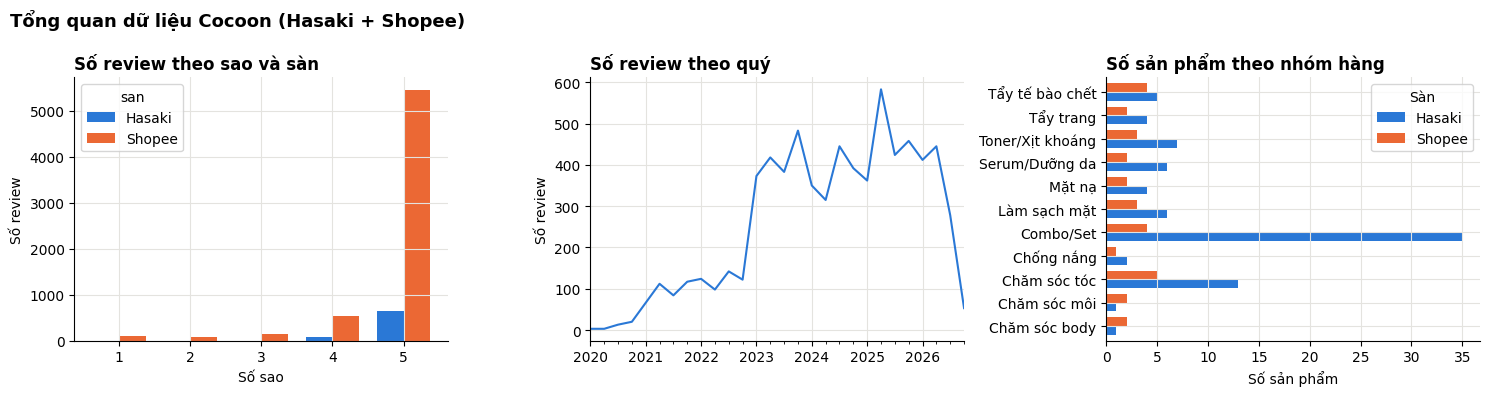

In [5]:
# ---- Khám phá nhanh dữ liệu (EDA) ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
reviews.groupby(["san", "sao"]).size().unstack(0).fillna(0).plot.bar(ax=axes[0], color=[BLUE, ORANGE], width=0.75)
axes[0].set(title="Số review theo sao và sàn", xlabel="Số sao", ylabel="Số review")
axes[0].tick_params(axis="x", rotation=0)
reviews.groupby(reviews["date"].dt.to_period("Q")).size().plot(ax=axes[1], color=BLUE)
axes[1].set(title="Số review theo quý", xlabel="", ylabel="Số review")
products.groupby(["Category", "Sàn"]).size().unstack(fill_value=0).plot.barh(ax=axes[2], color=[BLUE, ORANGE], width=0.75)
axes[2].set(title="Số sản phẩm theo nhóm hàng", xlabel="Số sản phẩm", ylabel="")
finish(fig, "00_eda_tong_quan", "Tổng quan dữ liệu Cocoon (Hasaki + Shopee)")

**Nhận xét (từ biểu đồ và bảng phân bố số sao)**

- **Điểm sao dồn về 5★.** 6.113/7.078 review (86,4%) là 5★. Khi gần như ai cũng chấm 5★ thì điểm sao trung bình không phân biệt được sản phẩm tốt với sản phẩm chưa tốt; muốn biết khách phàn nàn điều gì phải đọc **nội dung chữ** (các phần A1, B3, C).
- **Hasaki không có review ≤ 3★.** Toàn bộ 737 review Hasaki chỉ là 4★ (83) và 5★ (654), còn 342 review ≤ 3★ đều thuộc Shopee (113 review 1★, 85 review 2★, 144 review 3★). Không thể kết luận khách Hasaki hài lòng hơn khách Shopee, vì dữ liệu Hasaki nhiều khả năng chỉ gồm review tích cực (do cách sàn hiển thị hoặc cách thu thập). Vì vậy bài phân loại A1 chỉ chạy trên Shopee.
- **Dữ liệu lệch về Shopee.** Shopee chiếm 6.341/7.078 review (89,6%), nên các kết quả về văn bản (B3, C) chủ yếu phản ánh khách Shopee.
- **Hai sàn được thu thập ở hai thời điểm khác nhau.** Review Hasaki dừng ở 20/10/2025, review Shopee kéo dài đến 17/10/2026; vì vậy từ quý 4/2025 trở đi đường theo quý chỉ còn là Shopee, và phần RFM tính mốc thời gian riêng cho từng sàn.
- **Theo thời gian.** Số review mỗi quý tăng từ vài chục (2020) lên khoảng 65–140 (2021–2022), rồi khoảng 300–480 từ năm 2023 và đạt đỉnh 583 ở quý 2/2025. Đoạn rơi ở cuối đường có hai lý do khác nhau: quý 4/2026 mới có 53 review vì dữ liệu chỉ đến giữa tháng 10; còn quý 3/2026 (278 review; tháng 8 và tháng 9 chỉ có 67 và 90 review, so với 121–168 review mỗi tháng trong bảy tháng đầu năm) là quý đã đủ ngày nhưng thấp hơn rõ rệt. Có thể nhu cầu giảm, cũng có thể review mới chưa kịp xuất hiện khi thu thập, nên chưa đủ cơ sở để kết luận.
- **Danh mục.** Nhóm Combo/Set có nhiều sản phẩm nhất (35 ở Hasaki, 4 ở Shopee), kế đó là Chăm sóc tóc (13 ở Hasaki, 5 ở Shopee). Điều này quan trọng cho phần A2: một phần lớn danh mục là combo với quy cách và giá rất khác nhau.
- **Lưu ý về nguồn dữ liệu Shopee.** 3.150/6.341 review Shopee (49,7%) trùng với file Sentiment: toàn bộ chỉ 4–5★, đúng 105 review cho mỗi sản phẩm (30 sản phẩm), dài tối đa 136 ký tự (trung bình 104). Phần còn lại là 3.191 review của chỉ 8 sản phẩm, dài hơn (trung bình 141 ký tự, tối đa 2.062) và chứa **toàn bộ 342 review ≤ 3★ (10,7% của phần này)**. Hai nhóm có tính chất rất khác nhau, nên tỉ lệ tiêu cực chung (5,4%) và tỉ lệ 5★ chung (86,4%) phụ thuộc vào việc trộn hai nhóm. Nếu nhóm 3.150 review là dữ liệu bổ sung, cần ghi rõ nguồn trong báo cáo và nên chạy lại kết quả khi loại nhóm này để so sánh.

# PHẦN A –MÔ HÌNH HỌC MÁY CÓ GIÁM SÁT

Cả hai bài đều chia dữ liệu **70% Train / 15% Validation / 15% Test**: Train để huấn luyện, Validation để chọn siêu tham số, Test chấm điểm cuối cùng một lần. Các bước tiền xử lý (TF-IDF, chuẩn hóa, one-hot) chỉ `fit` trên Train để không "nhìn trước" dữ liệu Validation/Test.

## A1. Phân loại – dự báo review tiêu cực (≤ 3★) trên Shopee

**Bài toán kinh doanh:** phát hiện sớm review tiêu cực để CSKH phản hồi trước khi đánh giá xấu lan rộng. Nhãn `y = 1` nếu ≤ 3★, ngược lại `y = 0`.

**Đầu vào:** TF-IDF nội dung review (1–2 từ) + độ dài, số dấu `!`, đã mua hàng, giá, % giảm giá, nhóm hàng. **Không** đưa số sao vào đầu vào vì nhãn được tạo từ số sao.

**Mô hình:** Logistic Regression, Decision Tree, Random Forest. Siêu tham số chọn theo F1 trên Validation; dùng `class_weight` để bù lớp tiêu cực quá ít.

**Cách đọc chỉ số** (TP = bắt đúng review xấu, FP = báo nhầm, FN = bỏ sót):
- **Accuracy** = (TP + TN) / tổng. Dễ đánh lừa khi lớp tiêu cực chỉ ~5%.
- **Recall** = TP / (TP + FN): bắt được bao nhiêu % review xấu thật. Thấp nghĩa là bỏ sót khách bức xúc.
- **Precision** = TP / (TP + FP): trong số review bị gắn cờ, bao nhiêu % thật sự xấu. Thấp nghĩa là CSKH tốn công vào cảnh báo sai.
- **F1**: trung bình điều hòa của Precision và Recall, dùng để chọn mô hình. **ROC-AUC, PR-AUC**: khả năng xếp review xấu lên trước, không phụ thuộc ngưỡng.

In [6]:
# ---- Chuẩn bị dữ liệu: chỉ lấy review Shopee, ghép thêm thông tin sản phẩm ----
dfc = reviews[reviews["san"] == "Shopee"].merge(
    sp[["Mã SP", "Giá bán", "Giảm giá (%)", "Category"]].rename(columns={"Mã SP": "ma_sp"}), on="ma_sp", how="left")
dfc["log_price"] = np.log1p(dfc["Giá bán"])
y_all = (dfc["sao"] <= NEG_STAR_MAX).astype(int).to_numpy()          # 1 = Tiêu cực

TEXT_COL = "text_clean"
NUM_COLS = ["len_chars", "n_words", "n_exclaim", "verified", "log_price", "Giảm giá (%)"]
CAT_COLS = ["Category"]
print(f"Số mẫu: {len(dfc):,} | Tiêu cực: {y_all.sum():,} ({y_all.mean():.1%}) → dữ liệu mất cân bằng")

i_tr, i_va, i_te = split_70_15_15(len(dfc), y_all)                   # stratify theo y
Xtr_df, Xva_df, Xte_df = dfc.iloc[i_tr], dfc.iloc[i_va], dfc.iloc[i_te]
ytr, yva, yte = y_all[i_tr], y_all[i_va], y_all[i_te]
print(f"Train {len(i_tr):,} | Val {len(i_va):,} | Test {len(i_te):,}")

pre_c = ColumnTransformer([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=3000, sublinear_tf=True), TEXT_COL),
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
])
Xtr = pre_c.fit_transform(Xtr_df)                                    # chỉ fit trên TRAIN
Xva, Xte = pre_c.transform(Xva_df), pre_c.transform(Xte_df)
feat_names = np.array([n.split("__", 1)[1] for n in pre_c.get_feature_names_out()])

Số mẫu: 6,341 | Tiêu cực: 342 (5.4%) → dữ liệu mất cân bằng
Train 4,438 | Val 951 | Test 952


In [7]:
# ---- Huấn luyện 3 mô hình: (Model, tham số cố định, lưới siêu tham số để chọn) ----
CLF_SPACE = {
    "Logistic Regression": (LogisticRegression,
                            dict(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
                            {"C": [0.1, 1, 10]}),
    "Decision Tree": (DecisionTreeClassifier,
                      dict(class_weight="balanced", random_state=RANDOM_STATE),
                      {"max_depth": [5, 10, 20], "min_samples_leaf": [2, 5]}),
    "Random Forest": (RandomForestClassifier,
                      dict(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
                      {"max_depth": [None, 20], "min_samples_leaf": [1, 3]}),
}
f1_ = lambda y, p: f1_score(y, p, zero_division=0)

clf_models, clf_pred, rows = {}, {}, []
for name, (Model, co_dinh, luoi) in CLF_SPACE.items():
    best_p = chon_tham_so(Model, co_dinh, luoi, Xtr, ytr, Xva, yva, f1_, True)      # chọn trên VALIDATION
    model = Model(**co_dinh, **best_p).fit(Xtr, ytr)
    pred, score = model.predict(Xte), model.predict_proba(Xte)[:, 1]                 # chấm trên TEST
    clf_models[name], clf_pred[name] = model, (pred, score)
    rows.append({"Mô hình": name, "Accuracy": accuracy_score(yte, pred),
                 "Precision": precision_score(yte, pred, zero_division=0), "Recall": recall_score(yte, pred, zero_division=0),
                 "F1-score": f1_(yte, pred), "ROC-AUC": roc_auc_score(yte, score),
                 "PR-AUC": average_precision_score(yte, score), "Tham số tốt nhất": str(best_p)})

clf_res = pd.DataFrame(rows).set_index("Mô hình")
save_table(clf_res.round(4), "A1_phan_loai_chi_so", index=True)
best_clf = clf_res["F1-score"].idxmax()
print("KẾT QUẢ TRÊN TẬP TEST:\n", clf_res.drop(columns=["Tham số tốt nhất"]).round(3).to_string())
print(f"→ Mô hình có F1 cao nhất: {best_clf}")
print(f"→ Mốc so sánh: đoán 'tất cả đều tích cực' đạt Accuracy {1 - yte.mean():.1%} nhưng bắt được 0 review tiêu cực")

KẾT QUẢ TRÊN TẬP TEST:
                      Accuracy  Precision  Recall  F1-score  ROC-AUC  PR-AUC
Mô hình                                                                    
Logistic Regression     0.911      0.359   0.808     0.497    0.949   0.559
Decision Tree           0.899      0.300   0.635     0.407    0.780   0.244
Random Forest           0.936      0.438   0.615     0.512    0.940   0.474
→ Mô hình có F1 cao nhất: Random Forest
→ Mốc so sánh: đoán 'tất cả đều tích cực' đạt Accuracy 94.5% nhưng bắt được 0 review tiêu cực


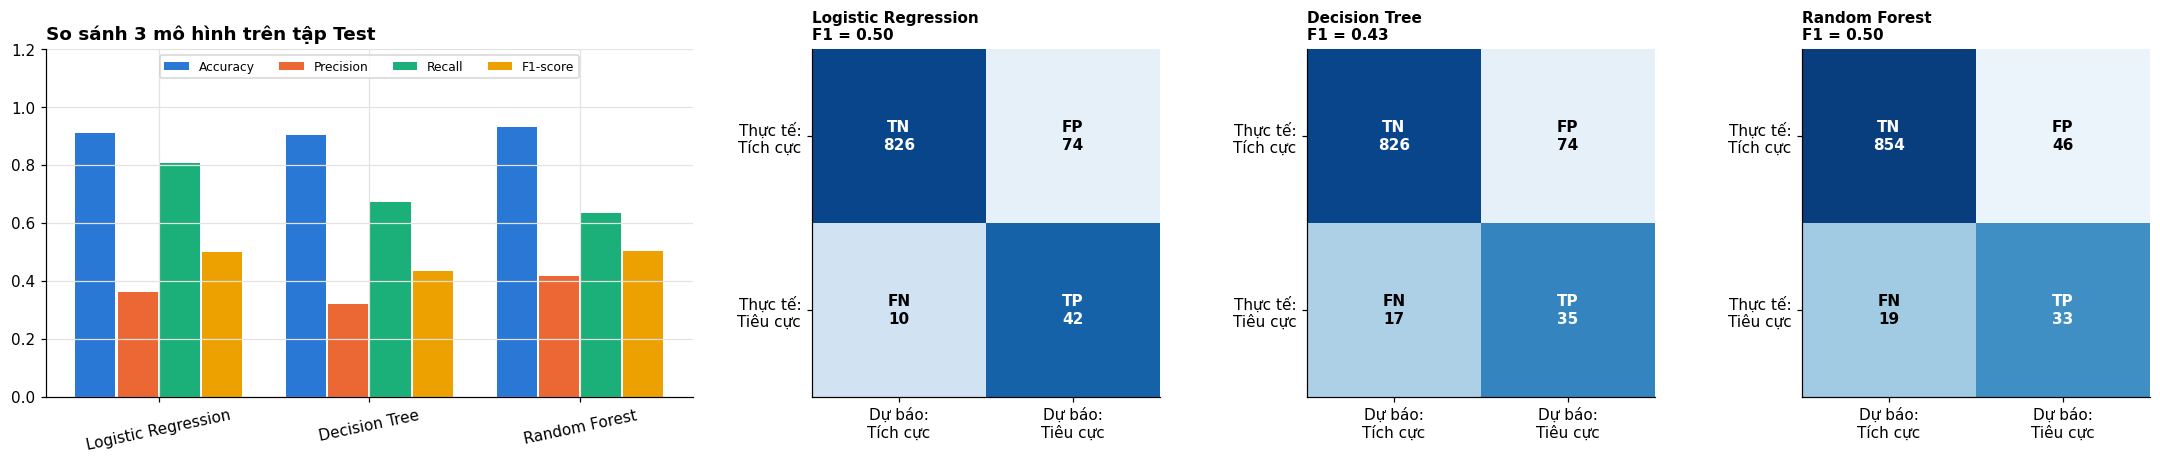

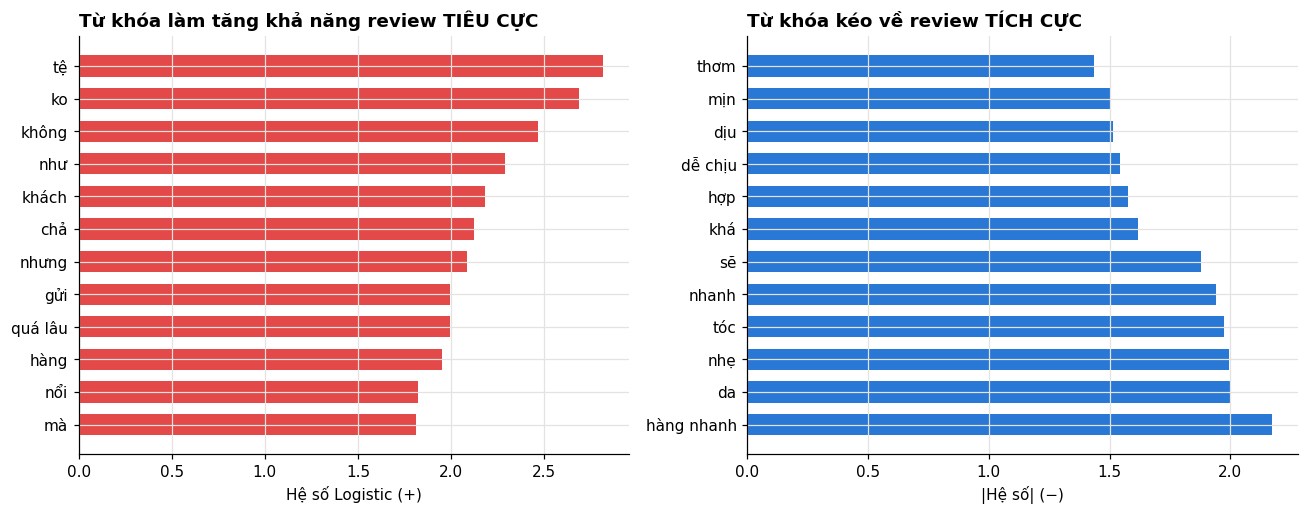

In [ ]:
# ---- (1) So sánh chỉ số + (2) ma trận nhầm lẫn ----
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), gridspec_kw={"width_ratios": [1.6, 1, 1, 1]})
for j, mt in enumerate(["Accuracy", "Precision", "Recall", "F1-score"]):
    axes[0].bar(np.arange(len(clf_res)) + (j - 1.5) * 0.2, clf_res[mt], 0.19, label=mt, color=CYCLE[j])
axes[0].set_xticks(range(len(clf_res)), clf_res.index, rotation=12)
axes[0].set(title="So sánh 3 mô hình trên tập Test", ylim=(0, 1.2))
axes[0].legend(ncol=4, fontsize=8, loc="upper center")
for ax, name in zip(axes[1:], CLF_SPACE):
    cm = confusion_matrix(yte, clf_pred[name][0])
    ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{['TN', 'FP', 'FN', 'TP'][2 * i + j]}\n{cm[i, j]:,}", ha="center", va="center",
                    fontweight="bold", color="white" if cm[i, j] / cm[i].sum() > 0.55 else "black")
    ax.set_xticks([0, 1], ["Dự báo:\nTích cực", "Dự báo:\nTiêu cực"])
    ax.set_yticks([0, 1], ["Thực tế:\nTích cực", "Thực tế:\nTiêu cực"])
    ax.set_title(f"{name}\nF1 = {clf_res.loc[name, 'F1-score']:.2f}", fontsize=10)
    ax.grid(False)
finish(fig, "A1_so_sanh_va_confusion_matrix")

# ---- (3) Từ khóa gắn với review tiêu cực / tích cực (hệ số Logistic) ----
coef = pd.Series(clf_models["Logistic Regression"].coef_[0], index=feat_names)
coef = coef[[f for f in feat_names if f not in NUM_COLS and not f.startswith("Category_")]]
top_neg, top_pos = coef.nlargest(12), coef.nsmallest(12)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].barh(top_neg.index[::-1], top_neg.values[::-1], color=RED, height=0.65)
axes[0].set(title="Từ khóa làm tăng khả năng review TIÊU CỰC", xlabel="Hệ số Logistic (+)")
axes[1].barh(top_pos.index, -top_pos.values, color=BLUE, height=0.65)
axes[1].set(title="Từ khóa kéo về review TÍCH CỰC", xlabel="|Hệ số| (−)")
finish(fig, "A1_tu_khoa")
save_table(pd.DataFrame({"tu_khoa_tieu_cuc": top_neg.index, "he_so": top_neg.values}), "A1_tu_khoa_tieu_cuc")

In [ ]:
# ---- Chọn ngưỡng cảnh báo cho CSKH (dùng mô hình có F1 cao nhất) ----
score_best = clf_pred[best_clf][1]
th_tab = pd.DataFrame([{"Ngưỡng": th, "Số cảnh báo": int((score_best >= th).sum()),
                        "Recall": ((score_best >= th) & (yte == 1)).sum() / yte.sum(),
                        "Precision": ((score_best >= th) & (yte == 1)).sum() / max((score_best >= th).sum(), 1)}
                       for th in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]])
save_table(th_tab.round(4), "A1_bang_nguong_canh_bao")
print(f"Bảng chọn ngưỡng ({best_clf}, Test = {len(yte)} review, trong đó {yte.sum()} review tiêu cực):")
print(th_tab.round(3).to_string(index=False))

# ---- Danh sách review bị gắn cờ ở ngưỡng đã chọn ----
alerts = Xte_df[["ma_sp", "sao", "text"]].assign(xac_suat_tieu_cuc=score_best)
alerts["text"] = alerts["text"].astype(str).str.slice(0, 110)
alerts = alerts[alerts["xac_suat_tieu_cuc"] >= THRESHOLD].sort_values("xac_suat_tieu_cuc", ascending=False)
save_table(alerts.round(4), "A1_canh_bao_cskh")
print(f"\nNgưỡng {THRESHOLD}: gắn cờ {len(alerts)}/{len(Xte_df)} review. 5 review rủi ro cao nhất:")
print(alerts.head(5).round(3).to_string(index=False))

Bảng chọn ngưỡng (Random Forest, Test = 952 review, trong đó 52 review tiêu cực):
 Ngưỡng  Số cảnh báo  Recall  Precision
    0.3          219   0.942      0.224
    0.4          143   0.865      0.315
    0.5           79   0.635      0.418
    0.6           37   0.385      0.541
    0.7           13   0.154      0.615
    0.8            0   0.000      0.000

Ngưỡng 0.4: gắn cờ 143/952 review. 5 review rủi ro cao nhất:
 ma_sp  sao                                                                      text  xac_suat_tieu_cuc
 92253    1                                       Nhận đc chai này mà thất vọng quá ạ              0.757
105519    3 Packaging ko có seal, khi unbox hộp hàng thì bị bung rơi vòi ra trong hộp              0.745
101935    5                           Đóng hàng quá sơ sài, k có bọc chống sốc j hết.              0.743
 91747    4                                                Phải chi có loại bịch 500g              0.739
 92253    1                           Mình mua chun

**Nhận xét kinh tế (A1)** – tập Test có 952 review, trong đó 52 review tiêu cực (5,5%)

| Mô hình | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0,912 | 0,362 | **0,808** | 0,500 | **0,948** | **0,556** |
| Decision Tree | 0,904 | 0,321 | 0,673 | 0,435 | 0,801 | 0,283 |
| Random Forest | **0,932** | **0,418** | 0,635 | **0,504** | 0,943 | 0,461 |

1. **Không chọn mô hình theo Accuracy.** Chỉ cần đoán "mọi review đều tích cực" là đạt 94,5%, cao hơn cả ba mô hình (0,90–0,93), nhưng cách đoán đó bắt được 0 review tiêu cực. Giá trị của mô hình nằm ở việc phát hiện review xấu, nên phải đọc Recall, Precision và F1.
2. **Decision Tree yếu nhất** (F1 0,435; ROC-AUC 0,80; PR-AUC 0,28). **Random Forest có F1 cao nhất (0,504) nhưng chỉ hơn Logistic Regression (0,500) khoảng 0,004.** Với 52 review tiêu cực trong tập Test, mức chênh này không đủ để kết luận Random Forest tốt hơn. Hai mô hình khác nhau ở cách đánh đổi tại ngưỡng mặc định 0,5: Logistic Regression bắt 42/52 review xấu (bỏ sót 10) nhưng báo nhầm 74 review; Random Forest bắt 33/52 (bỏ sót 19) và báo nhầm 46 review. Về khả năng xếp hạng, Logistic Regression ngang hoặc nhỉnh hơn (ROC-AUC 0,948 so với 0,943; PR-AUC 0,556 so với 0,461): Random Forest thắng F1 nhờ Precision cao hơn, không phải nhờ phát hiện được nhiều review xấu hơn.
3. **Cả hai xếp hạng review khá tốt.** ROC-AUC khoảng 0,94–0,95; PR-AUC 0,46–0,56, gấp khoảng 8–10 lần mức ngẫu nhiên (0,055). Nghĩa là nội dung review đủ tín hiệu để quyết định nên đọc review nào trước.
4. **Ngưỡng cảnh báo nên chọn theo năng lực của CSKH, không mặc định 0,5** (bảng ngưỡng của Random Forest):
   - Ngưỡng 0,5: gắn cờ 79 review (8,3%), nhưng bỏ sót gần 4/10 review xấu (Recall 63,5%, bỏ sót 19/52).
   - Ngưỡng **0,4**: gắn cờ 143 review (15,0%), bắt được 45/52 review xấu (Recall 86,5%), Precision 31,5% (cứ khoảng 3 cảnh báo thì có 1 cảnh báo đúng).
   - Ngưỡng 0,3: bắt 49/52 (94,2%) nhưng phải xem 219 review (23,0%), Precision chỉ 22,4%.

   Nếu coi mất một khách bức xúc thiệt hơn tốn thêm vài phút đọc review thì **ngưỡng 0,4** là điểm cân bằng hợp lý, nên code dùng `THRESHOLD = 0.4`. Nếu đội CSKH ít người, có thể nâng lên 0,5 (xem 79 thay vì 143 review, nhưng bỏ sót thêm 12 review xấu). Precision ở đây tính theo số sao: trong 143 review bị gắn cờ có 98 review 4–5★, trong đó có những review thật sự chứa lời phàn nàn (mục 6), nên Precision tính theo số sao có thể thấp hơn giá trị thực của cảnh báo.
5. **Từ khóa (biểu đồ hệ số Logistic):**
   - *Tiêu cực:* "tệ", "chả" là lời chê trực tiếp; "ko", "không", "như", "nhưng", "mà" là dấu hiệu câu phàn nàn ("không như mong đợi", "tốt nhưng…"); "gửi", "quá lâu" gắn với giao hàng chậm, đóng gói lâu hoặc vấn đề quà tặng; "nổi" là "nổi mụn/nổi mẩn đỏ" sau khi dùng; "khách" thường nằm trong lời phàn nàn về cách shop xử lý với khách hàng (trong các review có từ này, 43% là ≤ 3★); "hàng" là từ chung chung nên tự nó chưa nói lên điều gì.
   - *Tích cực:* "hàng nhanh", "nhanh" là giao nhanh; "nhẹ", "dịu", "mịn", "thơm", "dễ chịu", "hợp", "khá" là trải nghiệm sản phẩm; "da", "tóc" xuất hiện khi khách mô tả cảm nhận sau khi dùng; "sẽ" thường đi với ý định mua lại.
   - **Tốc độ giao hàng xuất hiện ở cả hai phía** ("hàng nhanh", "nhanh" kéo về tích cực, "quá lâu" kéo về tiêu cực), nên đây là yếu tố vận hành quyết định khách khen hay chê.
   - Vì chưa tách từ tiếng Việt (ví dụ "không" cũng nằm trong "không kích ứng", là lời khen), các từ đơn chỉ mang tính gợi ý; muốn biết nguyên nhân thật phải đọc review bị gắn cờ.
6. **Review bị gắn cờ cho thấy vấn đề cụ thể.** Năm review rủi ro cao nhất gồm: thất vọng về sản phẩm và giao thiếu hàng (hai review 1★ của mã 92253, combo tẩy tế bào chết cà phê), hộp không có seal nên rơi vòi (mã 105519, 3★), đóng hàng sơ sài không có bọc chống sốc (mã 101935, **chấm 5★ nhưng nội dung chê**) và một góp ý muốn có loại bịch 500g (mã 91747, 4★). Cờ tập trung ở vài sản phẩm: bốn mã **86707 (son dưỡng dầu dừa 5g, 32 cờ), 101935 (sữa rửa mặt nghệ, 27), 91747 (nước tẩy trang bí đao 500ml, 23) và 92253 (combo tẩy tế bào chết cà phê, 18)** chiếm 100/143 cờ (70%); 49/52 review xấu thật trong tập Test cũng nằm ở năm mã (86707: 18; 92253: 11; 91747: 10; 101935: 7; 105519: 3). Toàn bộ 342 review ≤ 3★ của Shopee chỉ nằm ở 6/30 sản phẩm (86707: 94; 92253: 78; 91747: 75; 101935: 50; 105519: 28; 112793: 17), nên cần rà soát các sản phẩm này trước.

**Đề xuất triển khai**
- Review mới → mô hình chấm xác suất → từ ngưỡng 0,4 trở lên thì gắn cờ cho CSKH phản hồi sớm (xin lỗi, đổi trả, hoàn tiền).
- Chia việc theo nguyên nhân sau khi đọc review gắn cờ: giao chậm, thiếu hàng, đóng gói → vận hành/kho; kích ứng, không hiệu quả → tư vấn/R&D; thái độ shop → quản lý gian hàng.
- Mỗi tháng thống kê số cờ theo mã sản phẩm để phát hiện sản phẩm có vấn đề lặp lại.

**Hạn chế:** nhãn lấy từ số sao nên có nhiễu (có review 5★ nhưng nội dung chê); chỉ 342 review tiêu cực (5,4%) nên chỉ số dao động theo cách chia dữ liệu; chưa tách từ tiếng Việt; giá và % giảm giá là thuộc tính của sản phẩm nên giống nhau cho mọi review của sản phẩm đó; chỉ áp dụng cho Shopee vì Hasaki không có review ≤ 3★; gần một nửa dữ liệu Shopee (3.150/6.341 review, và 469/952 review của tập Test) thuộc nhóm toàn 4–5★ (xem nhận xét EDA), còn review tiêu cực chỉ nằm ở 8 sản phẩm còn lại (chiếm 10,7% của phần này). Precision phụ thuộc vào tỉ lệ review tiêu cực nên khi áp dụng cho review tự nhiên có thể cao hơn số liệu trên; Recall ít phụ thuộc vào tỉ lệ này hơn.

## A2. Hồi quy – dự báo doanh thu 30 ngày của sản phẩm (Hasaki)

**Bài toán kinh doanh:** doanh thu 30 ngày phụ thuộc vào những yếu tố nào (giá, giảm giá, mức độ tương tác, điểm đánh giá…) và sản phẩm nào đang bán *dưới* hoặc *trên* kỳ vọng?

**Quyết định thiết kế:**
- **Mục tiêu = log(1 + Doanh thu 30 ngày).** Doanh thu lệch phải mạnh, lấy log để vài sản phẩm "ngôi sao" không kéo lệch mô hình. Sai số trên thang log đọc là *sai số theo tỉ lệ* (gấp bao nhiêu lần).
- **Không dùng `Lượt bán` làm đặc trưng** vì Doanh thu ≈ Giá × Lượt bán, đưa vào là "lộ đáp án" (rò rỉ dữ liệu).
- **Đặc trưng:** giá, % giảm giá, điểm đánh giá TB, tổng lượt đánh giá, số review thu thập được, số review 12 tháng gần nhất, % đã mua hàng, độ dài review TB, cờ "mẫu nhỏ", nhóm hàng.
- **Mô hình:** Linear Regression, Decision Tree, Random Forest; chọn siêu tham số theo RMSE trên Validation.
- Chỉ có 84 sản phẩm (Test chỉ 13) nên **ngoài tập Test còn đánh giá chéo Repeated K-Fold 5×5**; hãy tin **R² đánh giá chéo** hơn R² Test. R² = 0 là ngang bằng việc luôn dự báo bằng trung bình; R² âm là tệ hơn.

In [ ]:
# ---- Chuẩn bị dữ liệu mức sản phẩm Hasaki ----
rv_h = reviews[reviews["san"] == "Hasaki"]
ref = rv_h["date"].max() + pd.Timedelta(days=1)
agg = rv_h.groupby("ma_sp").agg(n_rv=("sao", "size"), pct_verified=("verified", "mean"),
                                avg_len=("len_chars", "mean"), avg_star=("sao", "mean"))
n365 = rv_h[rv_h["date"] >= ref - pd.Timedelta(days=365)].groupby("ma_sp").size().rename("n_365")
dfr = ph.merge(agg, left_on="Mã SP", right_index=True, how="left").merge(n365, left_on="Mã SP", right_index=True, how="left")
for c_ in ["pct_verified", "avg_len", "avg_star"]:
    dfr[c_] = dfr[c_].fillna(dfr[c_].median())                          # SP chưa có review → điền trung vị
dfr["n_rv"], dfr["n_365"] = dfr["n_rv"].fillna(0), dfr["n_365"].fillna(0)

# Lấy log cho các biến lệch phải
dfr["log_price"] = np.log1p(dfr["Giá bán"])
dfr["log_total_reviews"] = np.log1p(dfr["Tổng lượt đánh giá"])
dfr["log_n_rv"], dfr["log_n365"] = np.log1p(dfr["n_rv"]), np.log1p(dfr["n_365"])
dfr["is_small_sample"] = dfr["Trang_Thai_Mau"].astype(str).str.contains("nhỏ").astype(int)
y_r = np.log1p(dfr["Doanh thu 30 ngày"]).to_numpy()

R_NUM = ["log_price", "Giảm giá (%)", "Điểm đánh giá TB", "log_total_reviews", "log_n_rv", "log_n365",
         "pct_verified", "avg_len", "avg_star", "is_small_sample"]
R_CAT = ["Category"]
i_tr_r, i_va_r, i_te_r = split_70_15_15(len(dfr))
print(f"Số sản phẩm: {len(dfr)} | Train {len(i_tr_r)} | Val {len(i_va_r)} | Test {len(i_te_r)}")

pre_r = ColumnTransformer([("num", StandardScaler(), R_NUM), ("cat", OneHotEncoder(handle_unknown="ignore"), R_CAT)])
Xr_tr = pre_r.fit_transform(dfr.iloc[i_tr_r])                           # chỉ fit trên TRAIN
Xr_va, Xr_te = pre_r.transform(dfr.iloc[i_va_r]), pre_r.transform(dfr.iloc[i_te_r])
ytr_r, yva_r, yte_r = y_r[i_tr_r], y_r[i_va_r], y_r[i_te_r]

Số sản phẩm: 84 | Train 58 | Val 13 | Test 13


In [ ]:
# ---- Huấn luyện 3 mô hình hồi quy ----
REG_SPACE = {
    "Linear Regression": (LinearRegression, {}, {}),
    "Decision Tree": (DecisionTreeRegressor, dict(random_state=RANDOM_STATE),
                      {"max_depth": [2, 3, 5], "min_samples_leaf": [2, 5]}),
    "Random Forest": (RandomForestRegressor, dict(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
                      {"max_depth": [3, 5, None], "min_samples_leaf": [1, 3]}),
}
rmse = lambda y, p: np.sqrt(mean_squared_error(y, p))

reg_best, rows = {}, []
for name, (Model, co_dinh, luoi) in REG_SPACE.items():
    reg_best[name] = chon_tham_so(Model, co_dinh, luoi, Xr_tr, ytr_r, Xr_va, yva_r, rmse, False)   # chọn trên VALIDATION
    pred = Model(**co_dinh, **reg_best[name]).fit(Xr_tr, ytr_r).predict(Xr_te)                      # chấm trên TEST
    rows.append({"Mô hình": name, "MAE": mean_absolute_error(yte_r, pred), "MSE": mean_squared_error(yte_r, pred),
                 "RMSE": rmse(yte_r, pred), "R²": r2_score(yte_r, pred), "Tham số tốt nhất": str(reg_best[name])})
reg_res = pd.DataFrame(rows).set_index("Mô hình")

# Đánh giá chéo 5 fold x 5 lần (ổn định hơn vì Test chỉ 13 mẫu). Pipeline giúp chuẩn hóa lại trong từng fold.
X_full = dfr[R_NUM + R_CAT]
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
rows = []
for name, (Model, co_dinh, _) in REG_SPACE.items():
    r = cross_validate(Pipeline([("pre", pre_r), ("m", Model(**co_dinh, **reg_best[name]))]), X_full, y_r, cv=cv,
                       scoring=("r2", "neg_root_mean_squared_error"))
    rows.append({"Mô hình": name, "R² (CV TB)": r["test_r2"].mean(), "R² (CV độ lệch)": r["test_r2"].std(),
                 "RMSE (CV TB)": -r["test_neg_root_mean_squared_error"].mean()})
cv_res = pd.DataFrame(rows).set_index("Mô hình")
save_table(reg_res.round(4), "A2_hoi_quy_chi_so_test", index=True)
save_table(cv_res.round(4), "A2_hoi_quy_chi_so_cv", index=True)
best_reg = cv_res["R² (CV TB)"].idxmax()
print("KẾT QUẢ TRÊN TẬP TEST (thang log):\n", reg_res.drop(columns=["Tham số tốt nhất"]).round(3).to_string())
print("\nĐÁNH GIÁ CHÉO 5×5-FOLD:\n", cv_res.round(3).to_string())
print(f"→ Tốt nhất theo R² (CV): {best_reg}")

KẾT QUẢ TRÊN TẬP TEST (thang log):
                      MAE    MSE   RMSE     R²
Mô hình                                      
Linear Regression  1.037  2.016  1.420  0.019
Decision Tree      0.827  1.534  1.239  0.253
Random Forest      0.890  1.481  1.217  0.279

ĐÁNH GIÁ CHÉO 5×5-FOLD:
                    R² (CV TB)  R² (CV độ lệch)  RMSE (CV TB)
Mô hình                                                     
Linear Regression       0.311            0.191         1.189
Decision Tree           0.303            0.297         1.196
Random Forest           0.329            0.297         1.171
→ Tốt nhất theo R² (CV): Random Forest


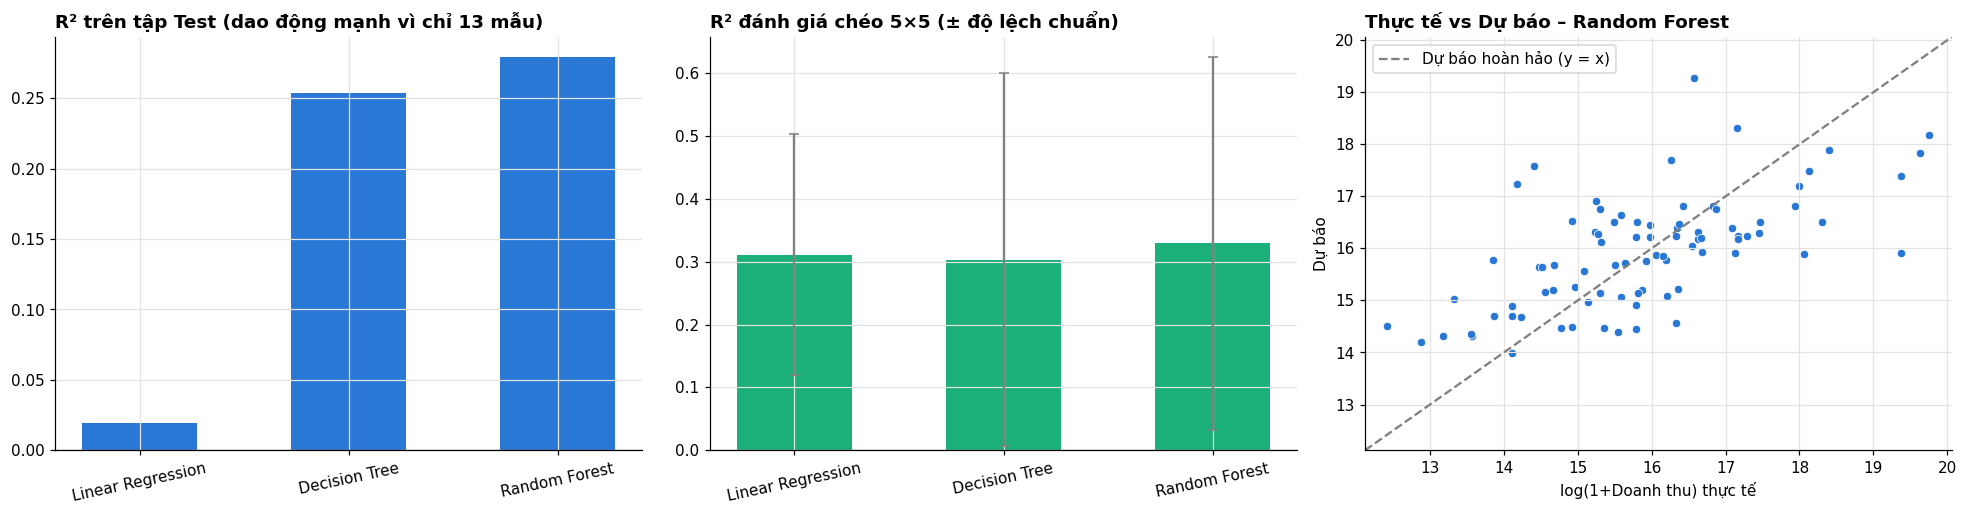

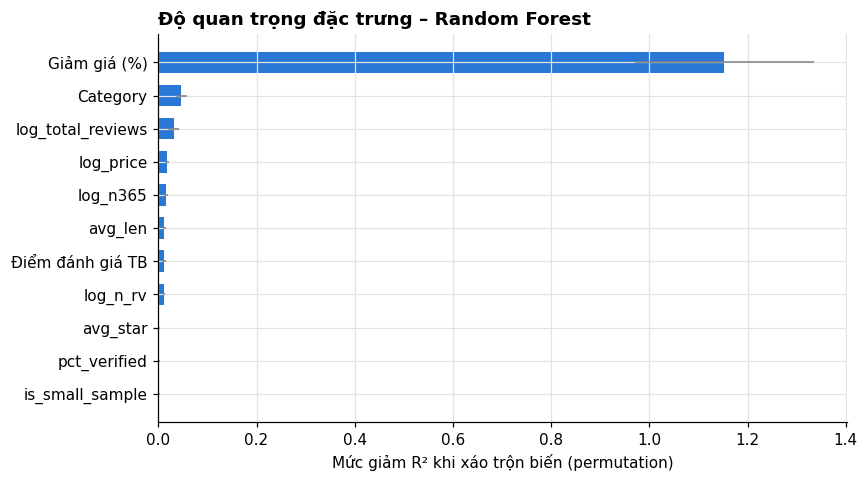

In [ ]:
# ---- Dự báo ngoài mẫu (out-of-fold) và độ quan trọng của đặc trưng ----
Model, co_dinh, _ = REG_SPACE[best_reg]
best_pipe = Pipeline([("pre", pre_r), ("m", Model(**co_dinh, **reg_best[best_reg]))])
oof = cross_val_predict(best_pipe, X_full, y_r, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))
resid = y_r - oof                                                       # phần dư: > 0 = bán TRÊN kỳ vọng

# Lưu ý: permutation importance tính trên chính 84 SP đã dùng để huấn luyện → chỉ để xếp thứ tự biến
pi = permutation_importance(best_pipe.fit(X_full, y_r), X_full, y_r, n_repeats=20, random_state=RANDOM_STATE)
pi_s = pd.Series(pi.importances_mean, index=R_NUM + R_CAT).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
x = np.arange(len(reg_res))
axes[0].bar(x, reg_res["R²"], 0.55, color=BLUE)
axes[0].set(title="R² trên tập Test (dao động mạnh vì chỉ 13 mẫu)")
axes[1].bar(x, cv_res["R² (CV TB)"], 0.55, yerr=cv_res["R² (CV độ lệch)"], color=AQUA, error_kw=dict(ecolor="gray", capsize=3))
axes[1].set(title="R² đánh giá chéo 5×5 (± độ lệch chuẩn)")
for ax in axes[:2]:
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xticks(x, reg_res.index, rotation=12)
lim = [min(y_r.min(), oof.min()) - 0.3, max(y_r.max(), oof.max()) + 0.3]
axes[2].scatter(y_r, oof, s=30, color=BLUE, edgecolor="white", linewidth=0.5)
axes[2].plot(lim, lim, ls="--", color="gray", label="Dự báo hoàn hảo (y = x)")
axes[2].set(title=f"Thực tế vs Dự báo – {best_reg}", xlabel="log(1+Doanh thu) thực tế", ylabel="Dự báo", xlim=lim, ylim=lim)
axes[2].legend()
finish(fig, "A2_hoi_quy")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(pi_s.index, pi_s.values, xerr=pi.importances_std[pd.Index(R_NUM + R_CAT).get_indexer(pi_s.index)],
        color=BLUE, height=0.65, error_kw=dict(ecolor="gray", lw=1))
ax.set(title=f"Độ quan trọng đặc trưng – {best_reg}", xlabel="Mức giảm R² khi xáo trộn biến (permutation)")
finish(fig, "A2_do_quan_trong_dac_trung")

In [ ]:
# ---- Sản phẩm bán trên / dưới kỳ vọng ----
rb = cv_res.loc[best_reg]
print(f"{best_reg}: R² (CV) = {rb['R² (CV TB)']:.2f} ± {rb['R² (CV độ lệch)']:.2f} | RMSE (CV) = {rb['RMSE (CV TB)']:.2f} (thang log)")
print(f"→ Sai số điển hình cỡ ×{np.exp(rb['RMSE (CV TB)']):.1f} so với doanh thu thực")
print("Ba biến mô hình dựa vào nhiều nhất: " + "; ".join(f"{k} (giảm R² {v:.2f})" for k, v in pi_s.sort_values(ascending=False).head(3).items()))

res_tab = pd.DataFrame({"Mã SP": dfr["Mã SP"], "Tên sản phẩm": dfr["Tên sản phẩm"].astype(str).str.slice(0, 45),
                        "Thực tế (triệu đ)": dfr["Doanh thu 30 ngày"] / 1e6, "Dự báo (triệu đ)": np.expm1(oof) / 1e6,
                        "Phần dư (log)": resid})
save_table(res_tab.round(3), "A2_phan_du_san_pham")
print("\nSản phẩm BÁN DƯỚI kỳ vọng (phần dư âm nhất):\n", res_tab.nsmallest(5, "Phần dư (log)").round(2).to_string(index=False))
print("\nSản phẩm BÁN TRÊN kỳ vọng (phần dư dương nhất):\n", res_tab.nlargest(5, "Phần dư (log)").round(2).to_string(index=False))

Random Forest: R² (CV) = 0.33 ± 0.30 | RMSE (CV) = 1.17 (thang log)
→ Sai số điển hình cỡ ×3.2 so với doanh thu thực
Ba biến mô hình dựa vào nhiều nhất: Giảm giá (%) (giảm R² 1.15); Category (giảm R² 0.05); log_total_reviews (giảm R² 0.03)

Sản phẩm BÁN DƯỚI kỳ vọng (phần dư âm nhất):
  Mã SP                                  Tên sản phẩm  Thực tế (triệu đ)  Dự báo (triệu đ)  Phần dư (log)
247927 Combo Cocoon Nước Cân Bằng Sen Hậu Giang 500m               1.80             43.02          -3.17
247923 Combo 2 Tinh Chất Cocoon Chiết Xuất Từ Nghệ H               1.44             30.67          -3.06
197365 Combo 2 Nước Cân Bằng Cocoon Sen Hậu Giang Là              15.74            235.96          -2.71
106535 Combo Cocoon Nước Dưỡng Tóc Tinh Dầu Bưởi 140               0.25              1.99          -2.08
248612 Mặt Nạ Cocoon Bí Đao Giảm Dầu & Mụn 100ml (Mớ               1.04              7.15          -1.93

Sản phẩm BÁN TRÊN kỳ vọng (phần dư dương nhất):
  Mã SP                           

**Nhận xét kinh tế (A2)** – 84 sản phẩm Hasaki, mục tiêu là log(1 + doanh thu 30 ngày)

| Mô hình | R² Test (13 SP) | RMSE Test | R² đánh giá chéo 5×5 | RMSE chéo |
|---|---|---|---|---|
| Linear Regression | 0,019 | 1,420 | 0,311 ± 0,191 | 1,189 |
| Decision Tree | 0,253 | 1,239 | 0,303 ± 0,297 | 1,196 |
| Random Forest | 0,279 | 1,217 | **0,329** ± 0,297 | **1,171** |

1. **Khả năng dự báo chỉ ở mức thấp đến trung bình.** R² chéo ≈ 0,33: các đặc trưng trong bảng giải thích khoảng một phần ba biến động doanh thu (thang log). Hai phần ba còn lại đến từ yếu tố không có trong dữ liệu như ngân sách quảng cáo, vị trí hiển thị, tồn kho, đợt sale.
2. **Ba mô hình ngang nhau.** R² chéo chỉ dao động 0,30–0,33 trong khi độ lệch chuẩn là 0,19–0,30, lớn hơn nhiều khoảng cách giữa các mô hình; Random Forest chỉ nhỉnh hơn khoảng 0,02 nên chưa thể coi là tốt hơn. Mô hình tuyến tính đơn giản làm gần bằng cây và rừng, nghĩa là chưa có bằng chứng về quan hệ phi tuyến phức tạp trong 84 quan sát này. R² Test của Linear Regression (0,02) thấp chủ yếu vì Test chỉ có 13 sản phẩm, không nên dùng riêng con số đó để loại mô hình.
3. **Sai số lớn.** RMSE chéo 1,17 trên thang log nghĩa là dự báo thường lệch khoảng **gấp 3,2 lần** (e^1,17): sản phẩm thực tế 100 triệu có thể bị dự báo từ ~31 đến ~320 triệu. Vì vậy chỉ dùng mô hình để **xếp hạng và phát hiện ngoại lệ**, không dùng làm con số dự báo doanh thu tuyệt đối.
4. **Biểu đồ thực tế – dự báo:** các điểm co về giữa (dự báo chỉ trải từ 14,0 đến 19,3 trong khi thực tế trải từ 12,4 đến 19,8). Bốn sản phẩm bán chạy nhất (log ≥ 19, doanh thu từ 259 triệu đồng trở lên) bị dự báo thấp hơn nhiều (khoảng 15,9–18,2), còn một số sản phẩm bán rất ít lại bị dự báo cao. Mô hình kém đúng ở hai đầu, chính là "ngôi sao" và "hàng ế" mà người quản lý quan tâm nhất.
5. **Biến quan trọng nhất là Giảm giá (%)**, vượt xa các biến khác: xáo trộn nó làm R² giảm 1,15, trong khi Category chỉ 0,05, tổng lượt đánh giá 0,03, giá bán khoảng 0,02 và các biến còn lại gần 0. Cần đọc thận trọng:
   - Độ quan trọng tính trên chính 84 sản phẩm đã dùng để huấn luyện nên bị thổi phồng; chỉ dùng để xếp thứ tự các biến.
   - Chỉ cho biết mô hình *dựa vào* biến nào, không cho biết giảm giá tăng thì doanh thu tăng hay giảm. Có thể sản phẩm bán chạy mới được sàn đẩy khuyến mãi (chiều nhân quả ngược); muốn biết tác động thật phải thử nghiệm A/B.
   - Cột này được đổi tên từ `% Chênh lệch giá` của Hasaki; cần kiểm tra lại đúng là % giảm giá so với giá niêm yết.
   - Điểm đánh giá, % đã mua hàng, độ dài review gần như không đóng góp, có thể vì review Hasaki chỉ có 4–5★ nên điểm sao ít phân biệt được các sản phẩm.
6. **Ngoại lệ gần như đều là combo/bộ.** Trong 10 sản phẩm lệch nhất, 8 là combo hoặc bộ. Bán *dưới* kỳ vọng: combo Nước cân bằng Sen Hậu Giang 500ml (thực tế 1,8 triệu so với dự báo 43 triệu), combo 2 tinh chất nghệ (1,4 so với 31 triệu), combo 2 nước cân bằng sen (15,7 so với 236 triệu), combo nước dưỡng tóc bưởi. Bán *trên* kỳ vọng: Bộ gội xả bưởi (259 so với 8 triệu), combo nước cân bằng sen 310ml (337 so với 55 triệu), combo nước tẩy trang bí đao, combo kem chống nắng. Cùng dòng Nước cân bằng Sen Hậu Giang nhưng có combo bán rất chạy, có combo gần như không bán được, cho thấy **quy cách, giá và cách đặt tên của từng combo quyết định kết quả**, và mô hình hiện chưa có biến nào mô tả điều đó.

**Đề xuất**
- Sản phẩm *bán dưới kỳ vọng*: rà soát hình ảnh, tiêu đề, giá, tồn kho, đánh giá xấu. Với các combo cùng dòng, so sánh trực tiếp combo bán tốt và combo bán kém (số lượng trong combo, giá trên mỗi ml, mức giảm).
- Sản phẩm *bán trên kỳ vọng*: tìm xem họ làm khác gì (thông điệp, quy cách, KOL, thời điểm sale) để nhân rộng.
- Cải tiến mô hình ở bước sau: thêm biến "là combo", "số món trong combo", "giá trên mỗi ml".

**Hạn chế:** chỉ 84 quan sát; doanh thu là ảnh chụp tại một thời điểm, chịu ảnh hưởng mùa vụ và đợt sale; thiếu ngân sách quảng cáo, vị trí hiển thị, tồn kho; chỉ áp dụng cho Hasaki.

# PHẦN B –MÔ HÌNH HỌC MÁY KHÔNG GIÁM SÁT

## B1. Phân khúc RFM (mức sản phẩm)

Dữ liệu không có mã khách hàng nên RFM được tính cho **sản phẩm** (đo "sức khỏe" của sản phẩm, không phải phân khúc khách hàng):

| Thành phần | Cách tính | Đọc như thế nào |
|---|---|---|
| **R** – Recency | Số ngày từ review gần nhất đến mốc tham chiếu của sàn | Càng nhỏ càng tốt |
| **F** – Frequency | Số review trong 365 ngày gần nhất | Đại diện cho mức độ tương tác |
| **M** – Monetary | Doanh thu 30 ngày | Quy mô doanh thu |

Mốc tham chiếu lấy theo review mới nhất của **từng sàn**; mỗi thành phần chấm **điểm 1–5 theo ngũ phân vị trong từng sàn**, nên "Champions" là sản phẩm nổi bật *trong sàn của nó*. Phân khúc gán theo luật, ưu tiên từ trên xuống: Champions (R, F, M ≥ 4) → Loyal (R, F, M ≥ 3) → At Risk (R ≤ 2 và F hoặc M ≥ 3) → Potential (R ≥ 3) → Hibernating (còn lại).

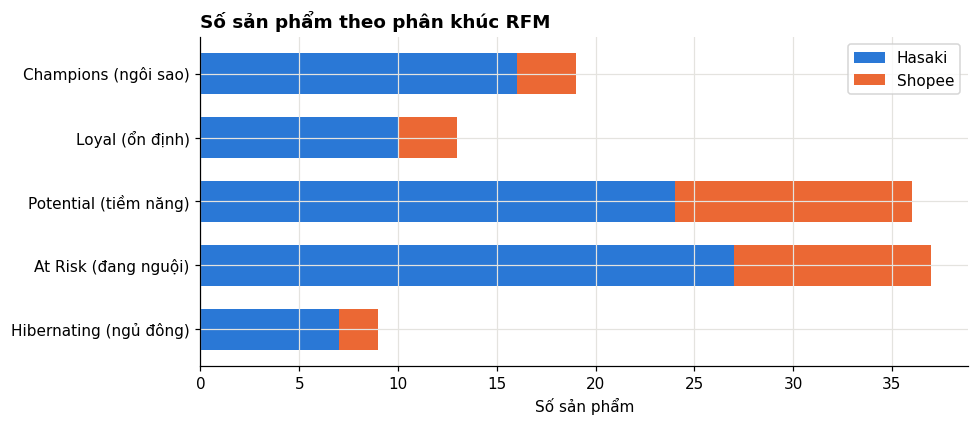

Số sản phẩm theo phân khúc và sàn:
 Sàn                     Hasaki  Shopee
Phân khúc RFM                         
Champions (ngôi sao)        16       3
Loyal (ổn định)             10       3
Potential (tiềm năng)       24      12
At Risk (đang nguội)        27      10
Hibernating (ngủ đông)       7       2

Trung bình R / F / M theo phân khúc (Monetary: triệu đồng, gộp hai sàn):
                         Recency  Frequency  Monetary
Phân khúc RFM                                       
Champions (ngôi sao)       67.2       19.4    2617.5
Loyal (ổn định)           420.1       36.2    2743.3
Potential (tiềm năng)     534.4       16.3    2420.3
At Risk (đang nguội)     1538.5        6.4    5095.6
Hibernating (ngủ đông)   1634.1        3.4    1449.9

Tỉ lệ sản phẩm 'nguội' (At Risk + Hibernating): Hasaki 40%, Shopee 40%


In [ ]:
# ---- Tính R, F, M cho từng sản phẩm ----
ref_date = reviews.groupby("san")["date"].max() + pd.Timedelta(days=1)       # mốc tham chiếu theo sàn
first_date = reviews.groupby("san")["date"].min()
rows = []
for _, p in products.iterrows():
    s = p["Sàn"]
    rv = reviews[(reviews["san"] == s) & (reviews["ma_sp"] == p["Mã SP"])]
    rec = (ref_date[s] - rv["date"].max()).days if len(rv) else (ref_date[s] - first_date[s]).days   # chưa có review → coi là rất cũ
    freq = int((rv["date"] >= ref_date[s] - pd.Timedelta(days=RFM_WINDOW_DAYS)).sum())
    rows.append({"Sàn": s, "Mã SP": p["Mã SP"], "Tên sản phẩm": p["Tên sản phẩm"], "Category": p["Category"],
                 "Recency": rec, "Frequency": freq, "Monetary": p["Doanh thu 30 ngày"]})
rfm = pd.DataFrame(rows)


# ---- Chấm điểm 1-5 theo ngũ phân vị trong từng sàn ----
def quintile(s, ascending=True):
    return pd.qcut(s.rank(method="first", ascending=ascending), 5, labels=[1, 2, 3, 4, 5]).astype(int)


rfm["R_score"] = rfm.groupby("Sàn")["Recency"].transform(lambda s: quintile(s, ascending=False))   # R nhỏ = điểm cao
rfm["F_score"] = rfm.groupby("Sàn")["Frequency"].transform(quintile)
rfm["M_score"] = rfm.groupby("Sàn")["Monetary"].transform(quintile)


def rfm_segment(r):
    R, F, M = r["R_score"], r["F_score"], r["M_score"]
    if R >= 4 and F >= 4 and M >= 4:
        return "Champions (ngôi sao)"
    if R >= 3 and F >= 3 and M >= 3:
        return "Loyal (ổn định)"
    if R <= 2 and (F >= 3 or M >= 3):
        return "At Risk (đang nguội)"
    if R >= 3:
        return "Potential (tiềm năng)"
    return "Hibernating (ngủ đông)"


rfm["Phân khúc RFM"] = rfm.apply(rfm_segment, axis=1)
SEG_ORDER = ["Champions (ngôi sao)", "Loyal (ổn định)", "Potential (tiềm năng)", "At Risk (đang nguội)", "Hibernating (ngủ đông)"]
seg_ct = rfm.groupby(["Phân khúc RFM", "Sàn"]).size().unstack(fill_value=0).reindex(SEG_ORDER).fillna(0).astype(int)
seg_mean = rfm.groupby("Phân khúc RFM")[["Recency", "Frequency", "Monetary"]].mean().reindex(SEG_ORDER)

fig, ax = plt.subplots(figsize=(9, 4))
seg_ct.plot.barh(ax=ax, stacked=True, color=[BLUE, ORANGE], width=0.65)
ax.invert_yaxis()
ax.set(title="Số sản phẩm theo phân khúc RFM", xlabel="Số sản phẩm", ylabel="")
ax.legend(title="")
finish(fig, "B1_rfm_phan_khuc")

print("Số sản phẩm theo phân khúc và sàn:\n", seg_ct.to_string())
print("\nTrung bình R / F / M theo phân khúc (Monetary: triệu đồng, gộp hai sàn):\n",
      seg_mean.assign(Monetary=seg_mean["Monetary"] / 1e6).round(1).to_string())
cold = (seg_ct / seg_ct.sum()).loc[["At Risk (đang nguội)", "Hibernating (ngủ đông)"]].sum()
print("\nTỉ lệ sản phẩm 'nguội' (At Risk + Hibernating): " + ", ".join(f"{s} {cold[s]:.0%}" for s in cold.index))

**Nhận xét kinh tế (RFM)** – 114 sản phẩm (84 Hasaki + 30 Shopee)

| Phân khúc | Hasaki | Shopee | Recency TB (ngày) | Frequency TB (review/năm) |
|---|---|---|---|---|
| Champions (ngôi sao) | 16 | 3 | 67 | 19,4 |
| Loyal (ổn định) | 10 | 3 | 420 | 36,2 |
| Potential (tiềm năng) | 24 | 12 | 534 | 16,3 |
| At Risk (đang nguội) | 27 | 10 | 1.538 | 6,4 |
| Hibernating (ngủ đông) | 7 | 2 | 1.634 | 3,4 |

1. **Chỉ khoảng 28% sản phẩm (32/114) vừa mới được nhắc đến vừa có nhiều tương tác** (Champions + Loyal). Champions chiếm 16/84 (19%) ở Hasaki và 3/30 (10%) ở Shopee.
2. **Có 40% sản phẩm đang "nguội" ở cả hai sàn** (At Risk + Hibernating: 34/84 ở Hasaki, 12/30 ở Shopee). Đây là nhóm lớn nhất cần xem xét danh mục.
3. **"Nguội" ở đây là rất lâu.** Recency trung bình của At Risk và Hibernating là 1.538 và 1.634 ngày (hơn 4 năm, có thể bị kéo lên bởi vài sản phẩm rất cũ). Trước khi chạy khuyến mãi "làm nóng" lại, cần kiểm tra sản phẩm còn được kinh doanh, còn tồn kho và còn hiển thị không. Cũng cần nhớ Recency tính theo *ngày review*, không phải ngày bán: sản phẩm vẫn có doanh thu nhưng không có review mới có thể do khách ít để lại đánh giá.
4. **Nhóm At Risk có Monetary trung bình cao nhất (khoảng 5,1 tỉ đồng, so với 2,6 tỉ của Champions).** Nghĩa là trong nhóm "nguội" có những sản phẩm doanh thu lớn, ưu tiên rà soát nhóm này trước khi xử lý Hibernating. Lưu ý các con số Monetary ở bảng trung bình gộp hai sàn; theo ghi chú của bản gốc, "Doanh thu 30 ngày" của Shopee là số tích lũy, nên chỉ nên dùng để so *thứ hạng trong cùng sàn*, không so giá trị tuyệt đối giữa Hasaki và Shopee (cần kiểm tra lại cách thu thập cột này).
5. **"Potential" là khái niệm tương đối.** Nhóm này có Recency trung bình 534 ngày (khoảng 1,5 năm), nghĩa là "còn mới" chỉ so với các sản phẩm khác trong cùng sàn.

| Phân khúc | Hành động gợi ý |
|---|---|
| Champions | Bảo đảm tồn kho và vị trí hiển thị, hạn chế giảm giá sâu, dùng làm sản phẩm "mồi" cho combo |
| Loyal | Duy trì; thử combo hoặc size lớn để tăng giá trị đơn |
| Potential | Tăng độ phủ: quảng cáo, seeding review/KOL, voucher dùng thử |
| At Risk | Kiểm tra sản phẩm còn bán/còn tồn kho; nếu còn thì làm mới nội dung, hình ảnh, flash sale; xem đối thủ và đánh giá xấu |
| Hibernating | Cân nhắc xả hàng hoặc ngưng nhập, không dồn ngân sách quảng cáo |

**Hạn chế:** đây là RFM của *sản phẩm*, không phải của khách hàng; F đếm *review* chứ không phải đơn hàng; Monetary của hai sàn không cùng nghĩa; chỉ 114 sản phẩm và nhiều sản phẩm bằng điểm nhau nên cách chia ngũ phân vị có phần tùy ý.

## B2. K-Means – phân cụm sản phẩm theo RFM

**Mục tiêu:** để dữ liệu tự chia sản phẩm thành các nhóm, *không dùng luật định sẵn* như RFM ở trên, rồi đối chiếu hai cách chia.

**Hàm mục tiêu:** J = Σₖ Σ₍ₓ∈Cₖ₎ ‖x − μₖ‖² (tổng bình phương khoảng cách từ mỗi điểm đến tâm cụm, gọi là *inertia*). Code tự tính J rồi so với `inertia_` của scikit-learn.

**Các bước:** log(1 + x) → chuẩn hóa z-score trong từng sàn → thử k = 1…10 (Elbow và Silhouette) → chọn k có Silhouette cao nhất trong khoảng 3–6 (hoặc đặt `K_CLUSTERS`) → đặt tên cụm theo tâm cụm.

**Vì sao giới hạn k từ 3 đến 6?** Chia thành 2 nhóm quá thô để ra quyết định quản lý sản phẩm; chia quá nhiều nhóm thì khó hành động.

In [ ]:
# ---- log → z-score trong từng sàn (bỏ chênh lệch thang đo giữa hai sàn) → K-Means ----
Xk = np.log1p(rfm[["Recency", "Frequency", "Monetary"]].astype(float))
Xk = Xk.groupby(rfm["Sàn"]).transform(lambda s: (s - s.mean()) / (s.std(ddof=0) + 1e-9)).to_numpy()

inertias, sils = {}, {}
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xk)
    inertias[k] = km.inertia_
    if k >= 2:
        sils[k] = silhouette_score(Xk, km.labels_)
cand = {k: v for k, v in sils.items() if 3 <= k <= 6}
K_FINAL = K_CLUSTERS or max(cand, key=cand.get)
print("Inertia J theo k :", {k: round(float(v), 1) for k, v in inertias.items()})
print("Silhouette theo k:", {k: round(float(v), 3) for k, v in sils.items()})
print(f"→ Chọn k = {K_FINAL}")

km = KMeans(n_clusters=K_FINAL, n_init=20, random_state=RANDOM_STATE).fit(Xk)
J_manual = sum(((Xk[km.labels_ == c] - km.cluster_centers_[c]) ** 2).sum() for c in range(K_FINAL))
print(f"J tự tính theo công thức = {J_manual:.4f} | km.inertia_ = {km.inertia_:.4f}")

# ---- Đặt tên cụm theo tâm cụm (z-score) ----
zc = pd.DataFrame(km.cluster_centers_, columns=["R", "F", "M"])
names = {}
for c in range(K_FINAL):
    r_, f_, m_ = zc.loc[c]
    names[c] = ("Nổi bật" if f_ + m_ - r_ > 1.2 else "Nguội/ít tương tác" if (r_ > 0.5 and f_ + m_ < 0)
                else "Doanh thu cao" if m_ > 0.3 else "Tương tác cao" if f_ > 0.3 else "Trung bình")
final_names = {c: f"Cụm {c + 1} – {names[c]}" for c in range(K_FINAL)}
rfm["Cụm K-means"] = km.labels_
rfm["Tên cụm"] = rfm["Cụm K-means"].map(final_names)

prof = rfm.groupby("Tên cụm").agg(So_SP=("Mã SP", "size"), Recency=("Recency", "mean"), Frequency=("Frequency", "mean"),
                                  Monetary=("Monetary", "mean"), Hasaki=("Sàn", lambda s: (s == "Hasaki").sum()),
                                  Shopee=("Sàn", lambda s: (s == "Shopee").sum()))
save_table(prof.round(2), "B2_kmeans_dac_trung_cum", index=True)
save_table(rfm, "B1_rfm_san_pham")                                       # bảng RFM kèm phân khúc và cụm
print("\nĐẶC TRƯNG CÁC CỤM:\n", prof.round(1).to_string())
print(f"\nSilhouette tại k = {K_FINAL}: {sils[K_FINAL]:.3f} "
      f"({'cấu trúc cụm khá rõ' if sils[K_FINAL] > 0.5 else 'cấu trúc yếu/vừa' if sils[K_FINAL] >= 0.25 else 'gần như không có cụm tự nhiên'})")
print("\nĐối chiếu cụm K-Means với phân khúc RFM theo luật:\n",
      pd.crosstab(rfm["Tên cụm"], rfm["Phân khúc RFM"]).reindex(columns=SEG_ORDER, fill_value=0).to_string())

Inertia J theo k : {1: 342.0, 2: 155.8, 3: 100.5, 4: 81.5, 5: 68.3, 6: 56.6, 7: 47.2, 8: 40.6, 9: 36.1, 10: 32.1}
Silhouette theo k: {2: 0.53, 3: 0.448, 4: 0.41, 5: 0.354, 6: 0.384, 7: 0.385, 8: 0.393, 9: 0.398, 10: 0.37}
→ Chọn k = 3
J tự tính theo công thức = 100.4563 | km.inertia_ = 100.4563

ĐẶC TRƯNG CÁC CỤM:
                        So_SP  Recency  Frequency      Monetary  Hasaki  Shopee
Tên cụm                                                                       
Cụm 1 – Doanh thu cao     37   1299.3        8.0  6.717117e+09      24      13
Cụm 2 – Nổi bật           34     55.5       35.1  2.579934e+09      26       8
Cụm 3 – Trung bình        43   1108.1        4.8  8.805670e+08      34       9

Silhouette tại k = 3: 0.448 (cấu trúc yếu/vừa)

Đối chiếu cụm K-Means với phân khúc RFM theo luật:
 Phân khúc RFM          Champions (ngôi sao)  Loyal (ổn định)  Potential (tiềm năng)  At Risk (đang nguội)  Hibernating (ngủ đông)
Tên cụm                                                  

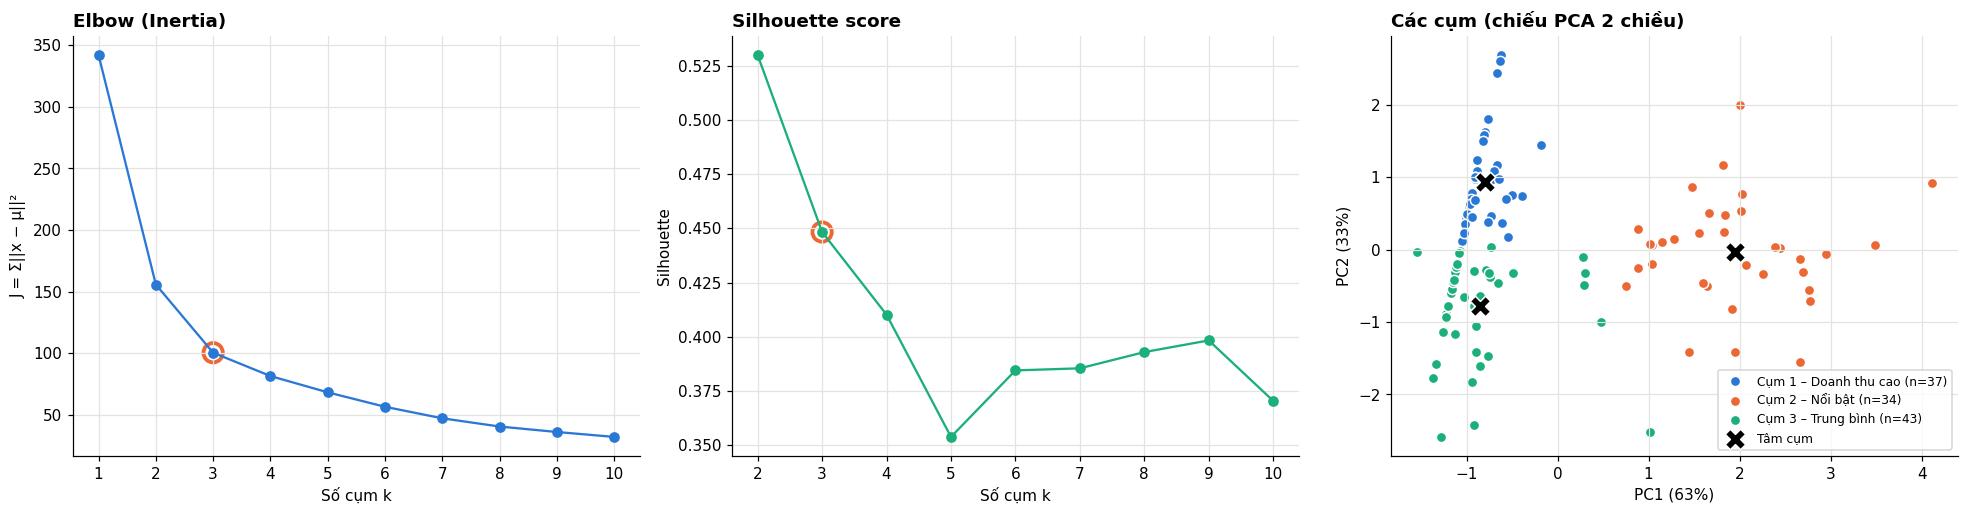

In [ ]:
# ---- Elbow, Silhouette và hình chiếu PCA 2 chiều ----
pca = PCA(2, random_state=RANDOM_STATE).fit(Xk)
Zk, Zc = pca.transform(Xk), pca.transform(km.cluster_centers_)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ks = list(inertias)
axes[0].plot(ks, list(inertias.values()), marker="o", color=BLUE)
axes[0].scatter([K_FINAL], [inertias[K_FINAL]], s=160, facecolor="none", edgecolor=ORANGE, lw=2.5)
axes[0].set(title="Elbow (Inertia)", xlabel="Số cụm k", ylabel="J = Σ||x − μ||²")
axes[0].set_xticks(ks)
axes[1].plot(list(sils), list(sils.values()), marker="o", color=AQUA)
axes[1].scatter([K_FINAL], [sils[K_FINAL]], s=160, facecolor="none", edgecolor=ORANGE, lw=2.5)
axes[1].set(title="Silhouette score", xlabel="Số cụm k", ylabel="Silhouette")
axes[1].set_xticks(list(sils))
for c in range(K_FINAL):
    m = km.labels_ == c
    axes[2].scatter(Zk[m, 0], Zk[m, 1], s=45, color=CYCLE[c], edgecolor="white", label=f"{final_names[c]} (n={m.sum()})")
axes[2].scatter(Zc[:, 0], Zc[:, 1], marker="X", s=180, color="black", edgecolor="white", label="Tâm cụm", zorder=5)
axes[2].set(title="Các cụm (chiếu PCA 2 chiều)", xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})",
            ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
axes[2].legend(fontsize=8)
finish(fig, "B2_kmeans")

**Nhận xét kinh tế (K-Means)**

| Cụm (k = 3) | Số SP (Hasaki / Shopee) | Recency TB (ngày) | Frequency TB | Monetary TB (tỉ đồng) | Đối chiếu với RFM theo luật |
|---|---|---|---|---|---|
| Cụm 1 – Doanh thu cao | 37 (24 / 13) | 1.299 | 8,0 | 6,72 | 29/37 là At Risk |
| Cụm 2 – Nổi bật | 34 (26 / 8) | 55 | 35,1 | 2,58 | 27/34 là Champions hoặc Loyal; 0 sản phẩm "nguội" |
| Cụm 3 – Trung bình | 43 (34 / 9) | 1.108 | 4,8 | 0,88 | 25/43 là Potential; 17/43 là At Risk hoặc Hibernating |

1. **Chọn k = 3 hợp lý.** Inertia giảm mạnh từ k = 1 đến 3 (342 → 156 → 100) rồi chậm hẳn (82 ở k = 4), tức đường Elbow gấp khúc ở k = 3. Silhouette cao nhất trong khoảng 3–6 cũng ở k = 3 (0,448). Silhouette của k = 2 cao hơn (0,53) nhưng chỉ chia được "còn tương tác" và "không", quá thô để hành động. J tự tính (100,46) khớp với `inertia_` của scikit-learn, xác nhận đúng công thức.
2. **Cấu trúc cụm ở mức vừa, không rõ nét.** Silhouette 0,448 nằm trong khoảng 0,25–0,5. Biểu đồ PCA cho thấy cụm "Nổi bật" tách khá xa về bên phải (PC1 giải thích 63%), còn "Doanh thu cao" và "Trung bình" nằm sát nhau ở bên trái, chỉ tách theo chiều PC2 (33%), tức ranh giới giữa hai cụm này chủ yếu dựa vào Monetary.
3. **Cụm 2 – Nổi bật (34 sản phẩm) là nhóm khỏe nhất:** review gần nhất cách đây trung bình 55 ngày, 35 review/năm. K-Means và RFM theo luật đồng thuận hoàn toàn ở nhóm này (không có sản phẩm "nguội"), nên kết luận chắc chắn: ưu tiên tồn kho, vị trí hiển thị, bảo vệ giá.
4. **Cụm 1 – Doanh thu cao (37 sản phẩm) là nhóm cần chú ý nhất.** Doanh thu trung bình cao nhất nhưng review gần nhất cách đây hơn 3,5 năm và chỉ 8 review/năm; 29/37 sản phẩm đồng thời là At Risk theo RFM. Tên "Doanh thu cao" do luật đặt tên chỉ nhấn vào Monetary, còn thực tế đây là **nhóm doanh thu lớn nhưng đang mất tương tác**. Nên kiểm tra trước: còn bán không, tồn kho, giá so với đối thủ, và lý do khách không để lại review mới (lưu ý Monetary của Shopee có thể là số tích lũy).
5. **Cụm 3 – Trung bình (43 sản phẩm):** doanh thu thấp nhất (0,88 tỉ), ít tương tác; trong đó 17 sản phẩm thuộc nhóm "nguội" theo RFM. Đây là nhóm để A/B test nội dung/khuyến mãi, hoặc cân nhắc ngưng nhập các sản phẩm nằm ở Hibernating.
6. **Chỗ hai cách chia lệch nhau cũng đáng xem:** 7 sản phẩm Potential nằm trong cụm Nổi bật, và 9 sản phẩm Hibernating đều nằm ở cụm Trung bình.

**Hạn chế:** chỉ 114 sản phẩm nên cụm có thể thay đổi nếu thêm dữ liệu; K-Means ưu tiên cụm hình cầu và nhạy với ngoại lai; tên cụm do luật tự đặt nên luôn phải đối chiếu với bảng đặc trưng cụm trước khi đưa vào báo cáo; Monetary của hai sàn không cùng nghĩa (đã chuẩn hóa z-score trong từng sàn để giảm vấn đề, nhưng bảng trung bình ở trên là số gốc gộp hai sàn).

## B3. Phân tích giỏ hàng – Luật kết hợp (Apriori và FP-Growth)

Dữ liệu không có đơn hàng nhiều sản phẩm, nên: **"giỏ hàng" = 1 review**, **"món hàng" = các khía cạnh khách nhắc tới** (mùi hương, giá, đóng gói, giao hàng…) cộng hai nhãn "Đánh giá 5★" / "Đánh giá ≤3★". Chỉ giữ giỏ có ≥ 2 mục. Luật **A → B** nghĩa là: khi review nhắc A thì thường nhắc thêm B.

| Thước đo | Công thức | Ý nghĩa |
|---|---|---|
| **Support** | P(A ∪ B) | Tỉ lệ review chứa cả A và B |
| **Confidence** | P(B \| A) = Support(A ∪ B) / Support(A) | Trong số review nhắc A, bao nhiêu % nhắc thêm B |
| **Lift** | Confidence / Support(B) | > 1: đi cùng nhau nhiều hơn ngẫu nhiên; ≈ 1: độc lập |

**Lift quan trọng hơn Confidence:** khía cạnh có mặt ở hầu hết review (như "Đánh giá 5★") cho Confidence rất cao nhưng Lift ≈ 1, không mang thông tin.

**Hai thuật toán** cùng tìm các tập khía cạnh xuất hiện đủ thường xuyên (Support ≥ ngưỡng) nên cho cùng kết quả; khác ở cách làm: **Apriori** sinh tập ứng viên theo từng mức rồi tỉa theo tính chất "tập con của tập phổ biến cũng phải phổ biến"; **FP-Growth** nén dữ liệu vào cây FP-Tree nên không cần sinh ứng viên và thường nhanh hơn. Code dùng thư viện `mlxtend` cho bước tìm tập phổ biến, còn Confidence và Lift tự tính để thấy rõ công thức.

In [ ]:
# ---- Mỗi review là một "giỏ": gồm các khía cạnh được nhắc tới (nhận diện bằng từ khóa) ----
ASPECTS = {
    "Mùi hương": r"thơm|mùi|hương",
    "Kết cấu mịn mượt": r"mịn|mượt|mềm|êm",
    "Làm sạch": r"sạch|tẩy|rửa",
    "Dưỡng ẩm": r"ẩm|dưỡng|căng",
    "Hiệu quả": r"hiệu quả|tác dụng|công dụng|cải thiện|giảm mụn|sáng da|mờ thâm|giảm gãy rụng|giảm dầu",
    "Dịu nhẹ/Lành tính": r"dịu|nhẹ nhàng|nhẹ|lành tính|nhạy cảm|không kích ứng|không rát|không cay|an toàn|thiên nhiên|thuần chay",
    "Giá tốt": r"giá|rẻ|hời|đáng tiền|tiết kiệm|sale|khuyến mãi|voucher",
    "Đóng gói": r"đóng gói|bao bì|gói hàng|hộp|chai|nắp|túi|tem",
    "Giao hàng": r"giao|ship|shipper|nhận hàng|vận chuyển",
    "Chính hãng": r"chính hãng|hàng việt|việt nam|uy tín",
    "Quay lại mua": r"mua lại|quay lại|ủng hộ|sẽ mua|ghiền|nghiện|lần sau|lọ thứ|chai thứ|dùng hoài|gắn bó",
    "Quà/Dịch vụ shop": r"tặng|quà|shop|tư vấn|nhiệt tình|cảm ơn",
    "Tóc": r"tóc|gội|gàu|dầu xả|chân tóc",
    "Da mặt/Mụn": r"mặt|mụn|lỗ chân lông|thâm|dầu nhờn",
    "Phàn nàn": r"tệ|kém|dở|thất vọng|hỏng|lỗi|đổ|vỡ|chậm|rát|kích ứng|nóng|không thơm|không như|giả|nhái|móp|rò|chảy|hết hạn|không hiệu quả",
}
# Bảng True/False: hàng = review, cột = khía cạnh. Dấu (?<!\w)...(?!\w) để khớp nguyên từ.
basket = pd.DataFrame({k: reviews["text_clean"].str.contains(rf"(?<!\w)(?:{v})(?!\w)", regex=True)
                       for k, v in ASPECTS.items()})
basket["Đánh giá ≤3★"] = reviews["sao"] <= NEG_STAR_MAX
basket["Đánh giá 5★"] = reviews["sao"] == 5
basket = basket[basket.sum(axis=1) >= 2].astype(bool)               # chỉ giữ review có >= 2 mục
print(f"Số giỏ (review có ≥ 2 mục): {len(basket):,} | số mục khác nhau: {basket.shape[1]}")

Số giỏ (review có ≥ 2 mục): 6,716 | số mục khác nhau: 17


In [ ]:
# ---- Tìm tập khía cạnh phổ biến bằng Apriori và FP-Growth, so sánh kết quả ----
t0 = time.time(); fi_ap = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True); t_ap = time.time() - t0
t0 = time.time(); fi_fp = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True); t_fp = time.time() - t0

sup_ap = dict(zip(fi_ap["itemsets"], fi_ap["support"]))
sup_fp = dict(zip(fi_fp["itemsets"], fi_fp["support"]))
same = sup_ap.keys() == sup_fp.keys() and all(abs(sup_ap[s] - sup_fp[s]) < 1e-9 for s in sup_ap)
print(f"Apriori  : {len(sup_ap)} tập phổ biến, {t_ap:.3f}s")
print(f"FP-Growth: {len(sup_fp)} tập phổ biến, {t_fp:.3f}s")
print(f"Hai thuật toán cho CÙNG kết quả: {same}")

# ---- Sinh luật A → B từ các tập phổ biến, lọc theo Confidence và Lift ----
rows = []
for itemset, sup in sup_fp.items():
    for r in range(1, len(itemset)):
        for A in map(frozenset, combinations(itemset, r)):
            B = itemset - A
            conf = sup / sup_fp[A]                  # Confidence = Support(A ∪ B) / Support(A)
            lift = conf / sup_fp[B]                 # Lift = Confidence / Support(B)
            if conf >= MIN_CONFIDENCE and lift > MIN_LIFT:
                rows.append({"Antecedent": " + ".join(sorted(A)), "Consequent": " + ".join(sorted(B)),
                             "Support": sup, "Confidence": conf, "Lift": lift})
rules = pd.DataFrame(rows).sort_values(["Lift", "Confidence"], ascending=False).reset_index(drop=True)
save_table(rules.round(4), "B3_luat_ket_hop")
print(f"\nSố luật (Confidence ≥ {MIN_CONFIDENCE:.0%}, Lift > {MIN_LIFT}): {len(rules)}")
print("Top 10 luật theo Lift:\n", rules.head(10).round(3).to_string())

Apriori  : 173 tập phổ biến, 0.126s
FP-Growth: 173 tập phổ biến, 0.042s
Hai thuật toán cho CÙNG kết quả: True

Số luật (Confidence ≥ 40%, Lift > 1.0): 148
Top 10 luật theo Lift:
                                    Antecedent               Consequent  Support  Confidence   Lift
0                 Quà/Dịch vụ shop + Đóng gói  Giao hàng + Đánh giá 5★    0.062       0.595  3.015
1   Quà/Dịch vụ shop + Đánh giá 5★ + Đóng gói                Giao hàng    0.062       0.670  2.927
2                 Quà/Dịch vụ shop + Đóng gói                Giao hàng    0.069       0.662  2.894
3         Da mặt/Mụn + Dưỡng ẩm + Đánh giá 5★                 Làm sạch    0.036       0.828  2.889
4                       Da mặt/Mụn + Dưỡng ẩm                 Làm sạch    0.042       0.823  2.873
5                       Da mặt/Mụn + Dưỡng ẩm   Làm sạch + Đánh giá 5★    0.036       0.723  2.799
6                       Giao hàng + Mùi hương   Đánh giá 5★ + Đóng gói    0.038       0.676  2.688
7                        Giao

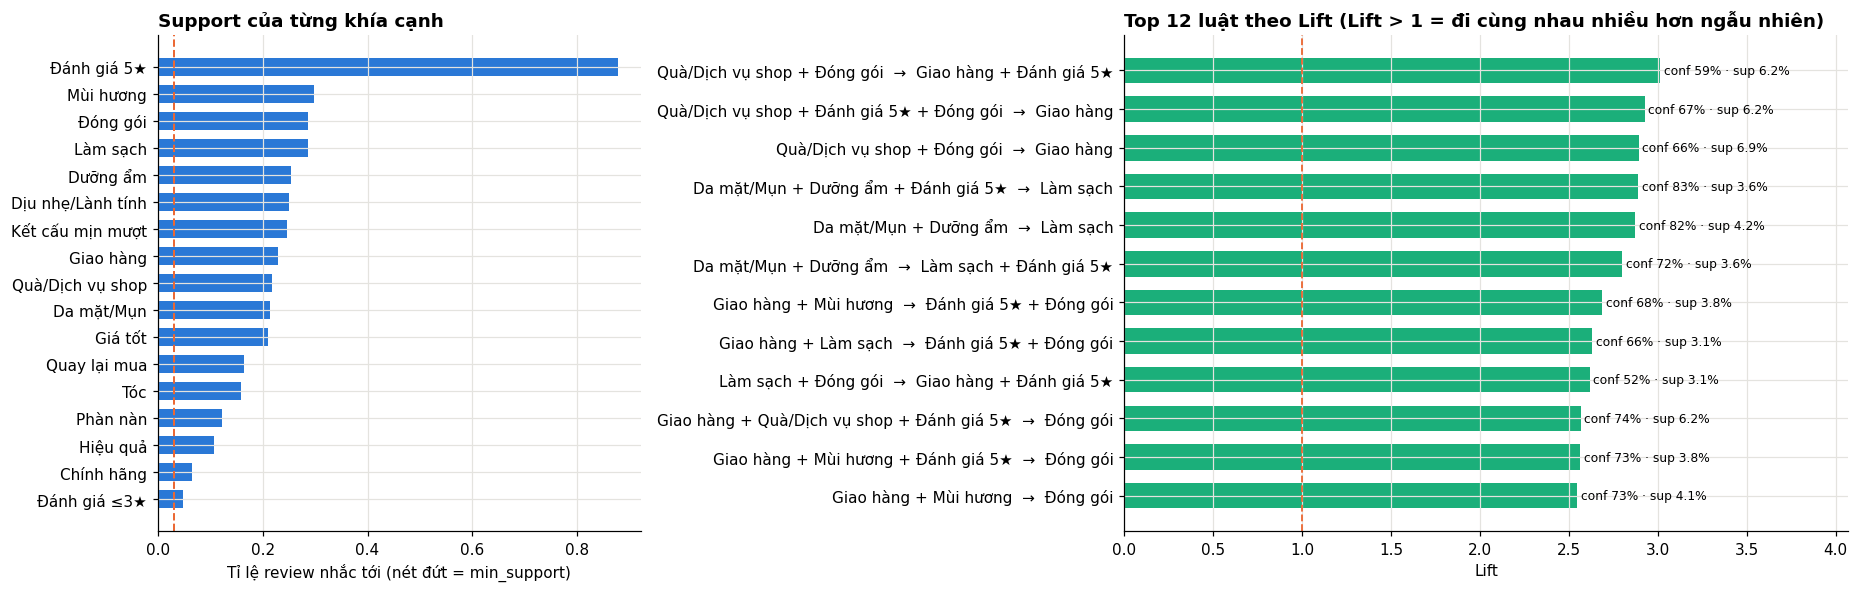

Luật dẫn tới đánh giá thấp / phàn nàn: chưa có luật nào vượt ngưỡng (thử hạ MIN_SUPPORT xuống 0.01).


In [ ]:
# ---- Biểu đồ: Support từng khía cạnh và Top 12 luật theo Lift ----
single = pd.Series({next(iter(s)): v for s, v in sup_fp.items() if len(s) == 1}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].barh(single.index, single.values, color=BLUE, height=0.68)
axes[0].axvline(MIN_SUPPORT, color=ORANGE, ls="--", lw=1.3)
axes[0].set(title="Support của từng khía cạnh", xlabel="Tỉ lệ review nhắc tới (nét đứt = min_support)")
if len(rules):
    top = rules.head(12).iloc[::-1]
    bars = axes[1].barh([f"{a}  →  {c_}" for a, c_ in zip(top["Antecedent"], top["Consequent"])], top["Lift"], color=AQUA, height=0.66)
    for b, conf, sup in zip(bars, top["Confidence"], top["Support"]):
        axes[1].text(b.get_width() + 0.02, b.get_y() + b.get_height() / 2, f"conf {conf:.0%} · sup {sup:.1%}", va="center", fontsize=8)
    axes[1].axvline(1, color=ORANGE, ls="--", lw=1.2)
    axes[1].set(title="Top 12 luật theo Lift (Lift > 1 = đi cùng nhau nhiều hơn ngẫu nhiên)", xlabel="Lift")
    axes[1].set_xlim(0, top["Lift"].max() * 1.35)
finish(fig, "B3_luat_ket_hop")

# ---- Có luật nào dẫn tới đánh giá thấp / phàn nàn không? ----
pain = rules[rules["Consequent"].str.contains("Đánh giá ≤3★|Phàn nàn")] if len(rules) else rules
if pain.empty:
    print("Luật dẫn tới đánh giá thấp / phàn nàn: chưa có luật nào vượt ngưỡng (thử hạ MIN_SUPPORT xuống 0.01).")
else:
    print("Luật dẫn tới đánh giá thấp / phàn nàn:\n", pain.head(5).round(3).to_string())

**Nhận xét kinh tế (luật kết hợp)** – 6.716 giỏ (review có ≥ 2 khía cạnh), 17 mục, 173 tập phổ biến, 148 luật

1. **Apriori và FP-Growth cho cùng kết quả** (173 tập phổ biến); FP-Growth thường chạy nhanh hơn Apriori; thời gian cụ thể phụ thuộc máy và phiên bản `mlxtend`, hãy đọc dòng in ở ô code. Với dữ liệu nhỏ như vậy chênh lệch thời gian không quan trọng, nhưng với dữ liệu hàng triệu giỏ hàng thì FP-Growth có lợi thế rõ.
2. **Biểu đồ Support:** "Đánh giá 5★" có mặt trong khoảng 88% giỏ nên các luật có vế sau là 5★ không đưa thêm thông tin (Lift tối đa chỉ khoảng 1,06; trần lý thuyết là 1/0,877 ≈ 1,14).
3. **Luật mạnh nhất tạo thành hai cụm rõ rệt:**
   - **Cụm trải nghiệm đơn hàng (Giao hàng – Đóng gói – Quà/Dịch vụ shop):** ví dụ "Quà/Dịch vụ shop + Đóng gói → Giao hàng" (Confidence 66%, Support 6,9%, Lift 2,9) và "Giao hàng + Mùi hương → Đóng gói" (Confidence 73%, Support 4,1%). Khách khen shop thường khen luôn giao hàng và đóng gói, tức họ đánh giá các khâu này như **một trải nghiệm chung**.
   - **Cụm sản phẩm cho da mặt:** "Da mặt/Mụn + Dưỡng ẩm → Làm sạch" (Confidence 82%, Support 4,2%, Lift 2,9). Review về da mặt và mụn khen cùng lúc khả năng làm sạch và dưỡng ẩm.
4. **Không có luật nào dẫn tới "Đánh giá ≤3★" hoặc "Phàn nàn"** vượt ngưỡng Support 3%. Vì review tiêu cực hiếm nên phân tích giỏ hàng *không tìm được điểm đau*; muốn tìm điểm đau phải dùng A1 (từ khóa tiêu cực) và C (chủ đề có tỉ lệ ≤ 3★ cao). Khía cạnh "Phàn nàn" xuất hiện ở khoảng 12% review, gấp hơn 2 lần tỉ lệ review ≤ 3★, cho thấy danh sách từ khóa này bắt cả những review không thật sự phàn nàn.

**Đề xuất**
- Chuẩn hóa thành cam kết dịch vụ "giao nhanh + đóng gói chắc" và đo bằng một chỉ số chung thay vì tách riêng.
- Trong nội dung bán hàng cho sản phẩm da mặt/da mụn, đặt cạnh nhau thông điệp "làm sạch" và "dưỡng ẩm" vì khách đang nhắc chúng cùng nhau.

**Hạn chế:** đây là các khía cạnh được nhắc *trong cùng một review*, **không phải hành vi mua kèm**, nên không dùng để kết luận "nên bán combo A + B"; tương quan không phải nhân quả; khía cạnh nhận diện bằng từ khóa nên có nhập nhằng; 89,6% review là của Shopee nên các luật chủ yếu phản ánh khách Shopee; gần một nửa review Shopee thuộc nhóm toàn 4–5★ (xem nhận xét EDA) nên tỉ lệ "Đánh giá 5★" và các khía cạnh tích cực có thể bị đẩy cao.

# PHẦN C – MÔ HÌNH NGOÀI NỘI DUNG MÔN HỌC

## C. Topic modeling (TF-IDF + NMF) trên nội dung review

**Mục tiêu:** tự động khám phá khách hàng đang nói về **chủ đề** nào, chủ đề nào gắn với đánh giá thấp, và hai sàn khác nhau ở đâu, không cần gắn nhãn thủ công.

**Cách làm:** lấy review không trùng lặp, dài ≥ 20 ký tự → loại từ phổ biến vô nghĩa (`VN_STOP`) → TF-IDF 1–2 từ → **NMF** (phân rã ma trận không âm) tách thành `N_TOPICS` chủ đề; mỗi review gán vào chủ đề có trọng số lớn nhất → tổng hợp theo chủ đề: số review, sao trung bình, tỉ lệ ≤ 3★, tỉ lệ Hasaki, từ khóa hàng đầu.

In [ ]:
VN_STOP = ["và", "là", "của", "cho", "mình", "rất", "thì", "có", "được", "này", "nhưng", "với", "mà", "cũng", "nên", "các", "những",
           "một", "khi", "để", "như", "đã", "sẽ", "ạ", "nha", "nhé", "thế", "ơi", "lắm", "quá", "luôn", "cả", "hơn", "vì", "nếu", "còn",
           "lại", "ra", "vào", "đó", "đây", "em", "chị", "anh", "bạn", "sản", "phẩm", "sp", "rồi", "mọi", "người", "thấy", "dùng", "xài",
           "mua", "k", "dc", "đc", "ko", "cocoon", "hơi", "ở", "tại", "từ", "trong", "sau", "trước", "nào", "thôi", "thui", "hết", "nữa",
           "bị", "ngày", "lần", "hay", "tôi", "mn", "r", "ok", "sử", "dụng", "cực", "kỳ", "tốt", "chưa"]

dft = reviews.drop_duplicates("text_clean")
dft = dft[dft["len_chars"] >= 20].reset_index(drop=True)
tfv = TfidfVectorizer(ngram_range=(1, 2), min_df=12, max_df=0.4, stop_words=VN_STOP, sublinear_tf=True)
Xt = tfv.fit_transform(dft["text_clean"])
vocab = np.array(tfv.get_feature_names_out())
print(f"Số review dùng: {len(dft):,} | số từ/cụm từ: {len(vocab):,}")

nmf = NMF(N_TOPICS, init="nndsvd", random_state=RANDOM_STATE, max_iter=600)
W, Hm = nmf.fit_transform(Xt), nmf.components_
dft["topic"] = W.argmax(axis=1)                                    # chủ đề có trọng số lớn nhất
topic_words = {t: list(vocab[Hm[t].argsort()[::-1][:10]]) for t in range(N_TOPICS)}


def short_label(words, n=3):
    # Nhãn gợi ý: ưu tiên cụm 2 từ, bỏ từ đơn đã nằm trong cụm đã chọn
    chosen = [w for w in words if " " in w][:2]
    for w in words:
        if len(chosen) < n and " " not in w and not any(w in c_.split() for c_ in chosen):
            chosen.append(w)
    return ", ".join(chosen[:n])


tsum = dft.groupby("topic").agg(So_review=("topic", "size"), Sao_TB=("sao", "mean"),
                                Ty_le_thap_sao=("sao", lambda s: (s <= NEG_STAR_MAX).mean()),
                                Ty_le_Hasaki=("san", lambda s: (s == "Hasaki").mean()))
tsum.insert(0, "Chủ đề", [f"T{t + 1}: " + short_label(topic_words[t]) for t in tsum.index])
tsum["Từ khóa hàng đầu"] = [", ".join(topic_words[t]) for t in tsum.index]
save_table(tsum.round(4), "C_topic_tong_hop")
print(tsum.round(3).to_string(index=False))

print("\nChủ đề có tỉ lệ review ≤3★ CAO NHẤT (điểm đau ưu tiên):")
for _, r_ in tsum.sort_values("Ty_le_thap_sao", ascending=False).head(3).iterrows():
    print(f"  • {r_['Chủ đề']}: {r_['Ty_le_thap_sao']:.1%} ≤3★ | sao TB {r_['Sao_TB']:.2f} | n = {int(r_['So_review']):,}")
print("Chủ đề có sao TB CAO NHẤT (điểm mạnh để truyền thông):")
for _, r_ in tsum.sort_values("Sao_TB", ascending=False).head(2).iterrows():
    print(f"  • {r_['Chủ đề']}: sao TB {r_['Sao_TB']:.2f} | n = {int(r_['So_review']):,}")

Số review dùng: 6,930 | số từ/cụm từ: 2,211
                        Chủ đề  So_review  Sao_TB  Ty_le_thap_sao  Ty_le_Hasaki                                                         Từ khóa hàng đầu
T1: giao hàng, hàng nhanh, gói        687   4.806           0.047         0.029 giao, giao hàng, hàng, gói, hàng nhanh, đóng, đóng gói, nhanh, thận, cẩn
     T2: bí đao, mụn lưng, dầu        722   4.881           0.010         0.065       mụn, bí, bí đao, đao, dầu, chân, lưng, mụn lưng, xịt mụn, kiềm dầu
    T3: da đầu, dưỡng tóc, gội        976   4.835           0.018         0.077            tóc, gội, bưởi, dưỡng, xịt, đầu, da đầu, rụng, mọc, dưỡng tóc
      T4: da chết, tẩy da, bào        734   4.843           0.030         0.195      tẩy, chết, da chết, tẩy da, bào, tế bào, tế, bào chết, body, tẩy tế
    T5: hoa hồng, tự nhiên, ẩm        806   4.887           0.005         0.037               ẩm, hồng, hoa hồng, hoa, tự nhiên, tự, nhiên, độ, rửa, mặt
   T6: chất lượng, ủng hộ, giá       1

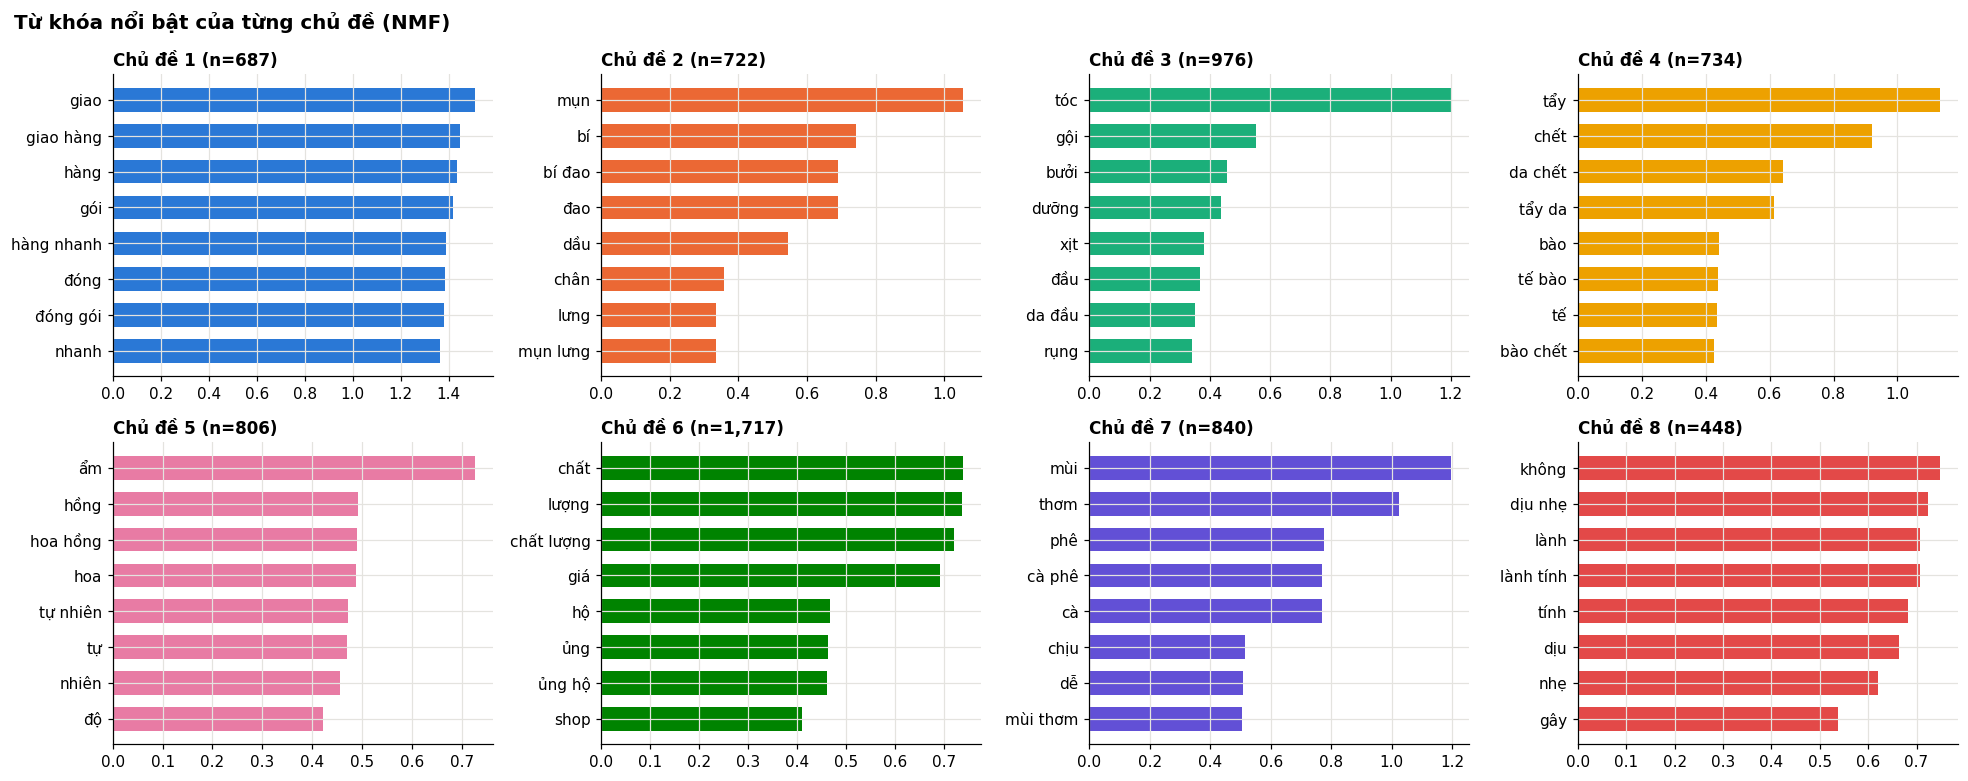

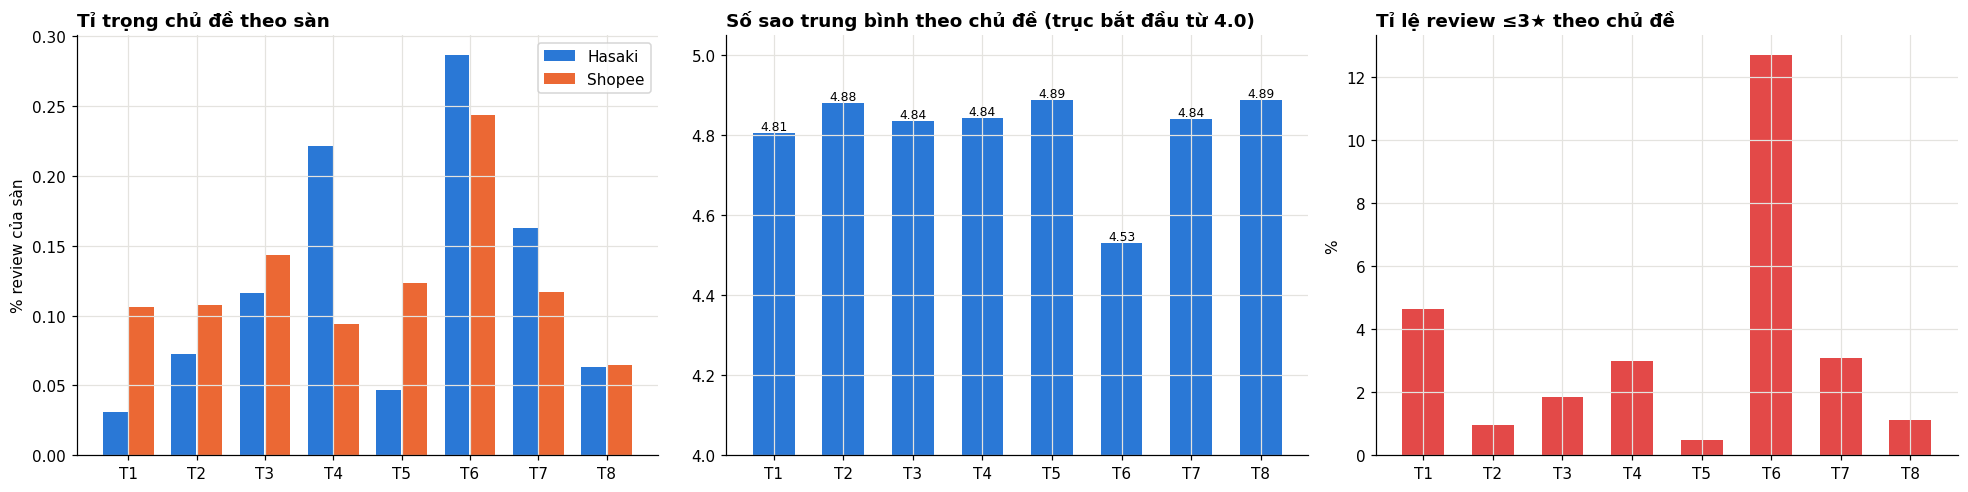

In [ ]:
# ---- Từ khóa từng chủ đề ----
nrow = ceil(N_TOPICS / 4)
fig, axes = plt.subplots(nrow, 4, figsize=(18, 3.6 * nrow))
for t, ax in zip(range(N_TOPICS), axes.ravel()):
    idx = Hm[t].argsort()[::-1][:8][::-1]
    ax.barh(vocab[idx], Hm[t][idx], color=CYCLE[t % 8], height=0.66)
    ax.set_title(f"Chủ đề {t + 1} (n={int((dft['topic'] == t).sum()):,})", fontsize=11)
for ax in axes.ravel()[N_TOPICS:]:
    ax.axis("off")
finish(fig, "C_topic_tu_khoa", "Từ khóa nổi bật của từng chủ đề (NMF)")

# ---- Tỉ trọng theo sàn, sao trung bình, tỉ lệ ≤3★ theo chủ đề ----
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
xt = np.arange(N_TOPICS)
share = pd.crosstab(dft["topic"], dft["san"], normalize="columns")
for j, s in enumerate(["Hasaki", "Shopee"]):
    axes[0].bar(xt + (j - 0.5) * 0.38, share[s].reindex(xt).fillna(0), 0.36, label=s, color=CYCLE[j])
axes[0].set(title="Tỉ trọng chủ đề theo sàn", ylabel="% review của sàn")
axes[0].legend()
y_min = min(4.0, tsum["Sao_TB"].min() - 0.1)                       # trục bắt đầu cao hơn 1 để thấy chênh lệch nhỏ
bars = axes[1].bar(xt, tsum["Sao_TB"].reindex(xt), 0.6, color=BLUE)
axes[1].bar_label(bars, fmt="%.2f", fontsize=8)
axes[1].set(title=f"Số sao trung bình theo chủ đề (trục bắt đầu từ {y_min:.1f})", ylim=(y_min, 5.05))
axes[2].bar(xt, tsum["Ty_le_thap_sao"].reindex(xt) * 100, 0.6, color=RED)
axes[2].set(title="Tỉ lệ review ≤3★ theo chủ đề", ylabel="%")
for ax in axes:
    ax.set_xticks(xt, [f"T{t + 1}" for t in xt])
finish(fig, "C_topic_san_sao")

**Nhận xét kinh tế (topic modeling)** – 6.930 review, 8 chủ đề. Nhãn T1–T8 do máy sinh; nếu thứ tự của bạn khác, hãy đối chiếu theo từ khóa trong bảng.

| Chủ đề | Nội dung (theo từ khóa) | Số review | Sao TB | Tỉ lệ ≤ 3★ | Tỉ lệ Hasaki |
|---|---|---|---|---|---|
| T1 | Giao hàng nhanh, đóng gói | 687 | 4,81 | 4,7% | 2,9% |
| T2 | Bí đao, mụn, kiềm dầu | 722 | 4,88 | 1,0% | 6,5% |
| T3 | Tóc, gội, bưởi, rụng tóc | 976 | 4,84 | 1,8% | 7,7% |
| T4 | Tẩy da chết, tẩy tế bào chết | 734 | 4,84 | 3,0% | 19,5% |
| T5 | Hoa hồng, tự nhiên, dưỡng ẩm | 806 | 4,89 | 0,5% | 3,7% |
| **T6** | **Chất lượng, giá, ủng hộ shop** | **1.717** | **4,53** | **12,7%** | 10,8% |
| T7 | Mùi thơm, cà phê, dễ chịu | 840 | 4,84 | 3,1% | 12,5% |
| T8 | Dịu nhẹ, lành tính, không gây (kích ứng) | 448 | 4,89 | 1,1% | 9,2% |

1. **Chỉ T6 là chủ đề nổi bật về điểm đau.** T6 lớn nhất (1.717 review, khoảng 25% toàn bộ) và có sao trung bình thấp nhất (4,53) cùng tỉ lệ ≤ 3★ cao nhất (12,7%, gấp 2,7 lần chủ đề cao thứ hai). Đây là nhóm review nói chung chung về **chất lượng và giá** (kèm "ủng hộ shop"), gồm cả lời khen lẫn lời chê. Khi khách chỉ nói "chất lượng/giá" mà không chỉ ra thuộc tính cụ thể nào, khả năng không hài lòng cao hơn hẳn. Việc cần làm tiếp: đọc mẫu review ≤ 3★ trong T6 để biết họ chê chất lượng ở điểm nào và có phải giá-kỳ-vọng không khớp.
2. **T1 (giao hàng, đóng gói) đứng thứ hai về tỉ lệ ≤ 3★ (4,7%)** và 97% là review Shopee. Kết quả này khớp với A1 ("quá lâu", "gửi" kéo về tiêu cực) và B3 (cụm giao hàng – đóng gói). Ba phép phân tích độc lập cùng chỉ ra **giao hàng/đóng gói trên Shopee là điểm vận hành cần cải thiện**; tuy vậy sao trung bình của T1 vẫn 4,81, nên đa số trải nghiệm giao hàng vẫn tốt.
3. **Các chủ đề về sản phẩm cụ thể đều được chấm cao** (sao TB 4,84–4,89, ≤ 3★ chỉ 0,5–3,1%): bí đao – mụn, tóc – bưởi, tẩy da chết, mùi cà phê, hoa hồng, dịu nhẹ. Hai chủ đề có tỉ lệ ≤ 3★ thấp nhất là **T5 (hoa hồng, tự nhiên, dưỡng ẩm, 0,5%)** và **T2 (bí đao, mụn, 1,0%)**; T8 (dịu nhẹ, lành tính) có sao TB cao nhất cùng T5. Đây là các thông điệp khách thật sự khen, nên đưa vào truyền thông. Lưu ý chênh lệch sao TB giữa các chủ đề này rất nhỏ (cùng khoảng 4,8–4,9), nên không nên xếp hạng chúng chặt chẽ.
4. **Hai sàn quan tâm khác nhau** (biểu đồ tỉ trọng): review Hasaki tập trung vào T4 tẩy da chết (khoảng 22% so với 9% ở Shopee), T7 mùi cà phê (khoảng 16% so với 12%) và T6 (khoảng 29% so với 24%); review Shopee phân bố đều hơn và có nhiều hơn về giao hàng T1 (khoảng 11% so với 3%), hoa hồng T5 (khoảng 12% so với 5%), tóc T3 và bí đao T2. Nói cách khác, khách Hasaki nhắc nhiều đến sản phẩm body (tẩy da chết, cà phê), còn khách Shopee nhắc nhiều đến dịch vụ giao hàng. Chủ đề "ủng hộ shop" (nằm trong T6) lại chiếm tỉ trọng *lớn hơn* ở Hasaki, nên không nên kết luận khách Shopee nhắc nhiều hơn về dịch vụ shop. review Hasaki chỉ chiếm khoảng 9% dữ liệu (646/6.930 review) nên tỉ trọng của Hasaki kém ổn định hơn.
5. **Biểu đồ sao trung bình có trục bắt đầu từ 4,0** để thấy được chênh lệch nhỏ; nếu vẽ từ 1 thì tất cả các cột gần như bằng nhau, và chỉ T6 hơi thấp. Đừng đọc chênh lệch chiều cao cột như chênh lệch lớn.

**Đề xuất:** giao T6 và T1 cho bộ phận phù hợp (chất lượng/giá cho sản phẩm; giao hàng/đóng gói cho vận hành Shopee); đưa T5, T8, T2 vào thông điệp quảng cáo; xây nội dung riêng cho từng sàn (Hasaki: sản phẩm body; Shopee: cam kết giao hàng).

**Hạn chế:** nhãn chủ đề do mình đặt dựa vào từ khóa nên mang tính diễn giải; mỗi review chỉ gán vào một chủ đề dù có thể nói nhiều chủ đề; chưa tách từ tiếng Việt; review Hasaki không có ≤ 3★ nên tỉ lệ ≤ 3★ theo chủ đề thực chất đo trên Shopee; gần một nửa review Shopee thuộc nhóm toàn 4–5★ có độ dài khá đồng đều (xem nhận xét EDA), có thể làm các chủ đề bị pha loãng và sao trung bình theo chủ đề cao hơn thực tế.

# Tổng kết

| Nội dung | Kết luận chính | Hành động |
|---|---|---|
| Điểm sao | 86% review là 5★; Hasaki không có review ≤ 3★ | Đọc nội dung chữ thay vì chỉ nhìn điểm sao; không so sánh mức hài lòng giữa hai sàn |
| A1 – Review tiêu cực | Bắt được khoảng 87% review xấu (45/52) khi gắn cờ ~15% review (ngưỡng 0,4), Precision ~31%; review xấu tập trung ở 6/30 sản phẩm Shopee | Triển khai bộ lọc cảnh báo cho CSKH; rà soát mã SP bị gắn cờ lặp lại |
| A2 – Doanh thu | R² chéo ≈ 0,33; sai số gấp ~3,2 lần; ngoại lệ chủ yếu là combo | Dùng để xếp hạng và tìm ngoại lệ, không dùng làm dự báo tuyệt đối |
| B1, B2 – Sản phẩm | 40% sản phẩm "nguội" ở cả hai sàn; 34 sản phẩm "Nổi bật" khỏe cả về tương tác lẫn doanh thu; 37 sản phẩm doanh thu cao nhưng lâu không có review mới | Bảo vệ nhóm Nổi bật; kiểm tra trạng thái của nhóm doanh thu cao nhưng nguội trước khi khuyến mãi |
| B3 – Luật kết hợp | Giao hàng – đóng gói – dịch vụ shop được khen cùng nhau; làm sạch – dưỡng ẩm – da mụn được khen cùng nhau | Chuẩn hóa cam kết giao hàng + đóng gói; ghép thông điệp làm sạch và dưỡng ẩm |
| C – Chủ đề | T6 (chất lượng, giá) có tỉ lệ ≤ 3★ 12,7%; giao hàng/đóng gói (T1) đứng thứ hai | Ưu tiên cải thiện chất lượng–giá kỳ vọng và giao hàng Shopee; truyền thông các điểm khách khen (dịu nhẹ, tự nhiên, dưỡng ẩm) |

**Hạn chế chung:** dữ liệu là review đã được sàn hiển thị nên thiên về tích cực; Hasaki chỉ có review 4–5★; chỉ có 84 + 30 sản phẩm; gần một nửa review Shopee (3.150/6.341) là nhóm toàn 4–5★, đúng 105 review mỗi sản phẩm, còn toàn bộ review ≤ 3★ nằm ở 8 sản phẩm còn lại; Monetary của hai sàn có thể không cùng nghĩa; các mối liên hệ tìm được là tương quan, muốn kết luận tác động (giảm giá, đổi quy cách combo) cần thử nghiệm A/B.